In [2]:
# Comentarios para Google Colab:
# 1) Monta Google Drive y ajusta rutas:
from google.colab import drive
drive.mount('/content/drive')
BASE_DATA_DIR = "/content/drive/MyDrive/TEG02-2025Arellano/Data"
GLICKO_REPO_PATH = "/content/drive/MyDrive/TEG02-2025Arellano/Data/GlickoSoccer-master"
# 2) Verifica dependencias si hace falta:
!pip install lightgbm scikit-learn seaborn joblib confz
# torch y tensorflow dependen del runtime seleccionado en Colab

Mounted at /content/drive


In [3]:
# === Selector de modo de entrenamiento ===
# Modos disponibles: "sanity" | "fast" | "deep" | "exhaustive"
TRAINING_MODE = "deep"  # cambia aqui segun lo que quieras ejecutar

# Comentarios para Google Colab:
# 1) Monta Google Drive y ajusta rutas:
#    from google.colab import drive
#    drive.mount('/content/drive')
#    BASE_DATA_DIR = "/content/drive/MyDrive/TEG/AplanarDatos"
#    GLICKO_REPO_PATH = "/content/drive/MyDrive/Glicko2Soccer/GlickoSoccer-master"
# 2) Verifica dependencias si hace falta:
#    !pip install lightgbm scikit-learn seaborn joblib
#    # torch y tensorflow dependen del runtime seleccionado en Colab

# Rutas base (ajusta si estas en Colab)
#BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"
#GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"

# Flags globales controlados por el selector
# Por seguridad inicializamos las banderas
RUN_FULL_TRAINING = False
RUN_SANITY_CHECK = False
FAST_MODE = False
EXHAUSTIVE_MODE = False
DEBUG_MODE = False

if TRAINING_MODE == "sanity":
    # Sanity: no ejecutar todo el entrenamiento largo; se usa DEBUG_MODE para
    # ejecutar el proceso completo pero sobre un subconjunto (df.head(100)).
    RUN_FULL_TRAINING = False
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = True
elif TRAINING_MODE == "fast":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = True
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = False
elif TRAINING_MODE == "deep":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = False
    DEBUG_MODE = False
elif TRAINING_MODE == "exhaustive":
    RUN_FULL_TRAINING = True
    RUN_SANITY_CHECK = True
    FAST_MODE = False
    EXHAUSTIVE_MODE = True
    DEBUG_MODE = False
else:
    raise ValueError(f"TRAINING_MODE invalido: {TRAINING_MODE}")

In [6]:
import sys
import os
import json
import time
import math
import importlib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, log_loss, accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from scipy.special import iv, gammaln
from scipy.optimize import minimize
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Optional ML frameworks (keep notebook import-safe)
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
except Exception:
    torch = None
    nn = None
    Dataset = None
    DataLoader = None

try:
    import tensorflow as tf
    from tensorflow import keras
except Exception:
    tf = None
    keras = None

# Workspace path for GlickoSoccer repo (needed before importing modules from it)
if "GLICKO_REPO_PATH" not in globals():
    GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"
if not os.path.exists(GLICKO_REPO_PATH):
    raise FileNotFoundError(
        "No se encontro el repo GlickoSoccer. Ajusta GLICKO_REPO_PATH en el selector de modo."
    )
sys.path.insert(0, GLICKO_REPO_PATH)

# Local modules
from G2Av1513 import Glicko2G2A, RatingG2A
from soccer.glicko_soccer import GlickoSoccer
import glicko2 as glicko2_lib

In [7]:
import sys
import os
import json
import time
import math
import importlib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, log_loss, accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from scipy.special import iv, gammaln
from scipy.optimize import minimize
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Optional ML frameworks (keep notebook import-safe)
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
except Exception:
    torch = None
    nn = None
    Dataset = None
    DataLoader = None

try:
    import tensorflow as tf
    from tensorflow import keras
except Exception:
    tf = None
    keras = None

# Workspace path for GlickoSoccer repo (needed before importing modules from it)
if "GLICKO_REPO_PATH" not in globals():
    GLICKO_REPO_PATH = r"C:\Users\ruben\Documents\Universidad\TEG\Glicko2Soccer\GlickoSoccer-master"
if not os.path.exists(GLICKO_REPO_PATH):
    raise FileNotFoundError(
        "No se encontro el repo GlickoSoccer. Ajusta GLICKO_REPO_PATH en el selector de modo."
    )
sys.path.insert(0, GLICKO_REPO_PATH)

# Local modules
from G2Av1513 import Glicko2G2A, RatingG2A
from soccer.glicko_soccer import GlickoSoccer
import glicko2 as glicko2_lib

# Carga de los CSV
if "BASE_DATA_DIR" not in globals():
    BASE_DATA_DIR = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos"

def resolve_path(candidates):
    for path in candidates:
        if path and os.path.exists(path):
            return path
    joined = "\n".join([str(p) for p in candidates])
    raise FileNotFoundError(
        "No se encontro ningun dataset. Revisa BASE_DATA_DIR y los nombres.\n" + joined
    )

# Modelo lite
ruta_lite = resolve_path([
    os.path.join(BASE_DATA_DIR, "matches_final_model_clean2.csv"),
    os.path.join(BASE_DATA_DIR, "matches_final_model_clean_scaled.csv"),
    os.path.join(BASE_DATA_DIR, "matches_final_model_clean.csv"),
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean2.csv",
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled.csv",
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean.csv",
])
df_completo_lite = pd.read_csv(ruta_lite)

# Comentar el modelo completo y el recortado si solo se desea usar 'lite'
ruta_full = resolve_path([
    os.path.join(BASE_DATA_DIR, "matches_final_model_full2.csv"),
    os.path.join(BASE_DATA_DIR, "matches_final_model_full_scaled.csv"),
    os.path.join(BASE_DATA_DIR, "matches_final_model_full.csv"),
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full2.csv",
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled.csv",
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full.csv",
])
df_completo_full = pd.read_csv(ruta_full)

df_lite = df_completo_lite.copy()
df_full = df_completo_full.copy()

def chronological_split_by_ratio(df, ratio=0.7):
    """Divide el DataFrame manteniendo el orden cronologico (por match_date_from_id)."""
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    return train_df, test_df

def _get_year_series(df, date_col='match_date_from_id'):
    if date_col not in df.columns:
        raise ValueError(f"Falta columna {date_col}")
    dt = pd.to_datetime(df[date_col], errors='coerce')
    if dt.notna().mean() < 0.5:
        dt = pd.to_numeric(df[date_col], errors='coerce')
        years = (dt // 10000).astype('Int64')
    else:
        years = dt.dt.year.astype('Int64')
    return years

def _get_date_series(df, date_col='match_date_from_id'):
    if date_col not in df.columns:
        raise ValueError(f"Falta columna {date_col}")
    dt = pd.to_datetime(df[date_col], errors='coerce')
    if dt.notna().mean() < 0.5:
        dt = pd.to_numeric(df[date_col], errors='coerce')
    return dt

def _extract_match_id_ymd(df, id_col='match_id_new'):
    if id_col not in df.columns:
        raise ValueError(f"Falta columna {id_col}")
    s = df[id_col].astype(str).str.slice(0, 8)
    y = pd.to_numeric(s.str.slice(0, 4), errors='coerce')
    m = pd.to_numeric(s.str.slice(4, 6), errors='coerce')
    d = pd.to_numeric(s.str.slice(6, 8), errors='coerce')
    return y, m, d

def add_pandemic_and_season(df):
    df2 = df.copy()
    # Pandemic (03/03/2020 - 06/06/2021)
    dt = _get_date_series(df2)
    dt_series = pd.to_datetime(dt, errors='coerce')
    y_mid, m_mid, d_mid = _extract_match_id_ymd(df2)
    dt_fallback = pd.to_datetime(
        y_mid.astype('Int64') * 10000 + m_mid.astype('Int64') * 100 + d_mid.astype('Int64'),
        format='%Y%m%d', errors='coerce'
    )
    dt_series = dt_series.fillna(dt_fallback)
    start = pd.Timestamp('2020-03-03')
    end = pd.Timestamp('2021-06-06')
    df2['pandemic'] = ((dt_series >= start) & (dt_series <= end)).astype(int)

    # Season desde match_id_new con reglas por competencia
    calendar_europe = [
    "Bundesliga",
    "ChampionsLeague",
    "EuropaLeague",
    "EuropaConferenceLeague",
    "LaLiga",
    "LigaMX",
    "Ligue1",
    "PremierLeague",
    "SaudiProLeague",
    "SerieA",
    "SuperLeagueGreece",
    ]
    afc_winter = ["AFCChampionsLeagueElite", "AFCChampionsTwo"]
    comp = df2['Competition'].astype(str)
    y = y_mid.fillna(dt_series.dt.year)
    m = m_mid.fillna(dt_series.dt.month)
    is_winter = comp.isin(calendar_europe)
    is_winter |= (comp == 'LigaArgentina') & (y <= 2020)
    is_winter |= comp.isin(afc_winter) & (y >= 2023)
    season = y.copy()
    season = np.where(is_winter & (m >= 8), y + 1, season)
    df2['season'] = pd.Series(season, index=df2.index, dtype="Int64")
    return df2

def chronological_split_by_year(df, year_cutoff, date_col='match_date_from_id'):
    """Split por anio: train < year_cutoff, test >= year_cutoff."""
    years = _get_year_series(df, date_col=date_col)
    train_mask = years < year_cutoff
    test_mask = years >= year_cutoff
    train_df = df.loc[train_mask].copy()
    test_df = df.loc[test_mask].copy()
    return train_df, test_df

# Recortar lite desde la primera fecha disponible en full (comentado si no se usa full)
full_min_date = _get_date_series(df_full).min()
if pd.isna(full_min_date):
    raise ValueError("No se pudo inferir la fecha minima de full")
lite_dates = _get_date_series(df_lite)
df_lite_recortado = df_lite.loc[lite_dates >= full_min_date].copy()

# Agregar columnas pandemic y season
df_lite = add_pandemic_and_season(df_lite)
df_full = add_pandemic_and_season(df_full)
df_lite_recortado = add_pandemic_and_season(df_lite_recortado)

# Bases para splits (modo debug usa 100 partidos por dataset)
df_lite_ratio_base = df_lite
df_full_ratio_base = df_full
df_lite_recortado_ratio_base = df_lite_recortado
df_lite_year_base = df_lite
df_full_year_base = df_full
df_lite_recortado_year_base = df_lite_recortado
if 'DEBUG_MODE' in globals() and DEBUG_MODE:
    print("DEBUG_MODE activo: preparando bases con 100 filas")
    df_lite_ratio_base = df_lite.head(100).copy()
    df_full_ratio_base = df_full.head(100).copy()
    df_lite_recortado_ratio_base = df_lite_recortado.head(100).copy()
    df_lite_year_base = df_lite.copy()
    df_full_year_base = df_full.copy()
    df_lite_recortado_year_base = df_lite_recortado.copy()

def _ensure_non_empty_split(df_sorted, train_df, test_df):
    if len(df_sorted) >= 2 and (len(train_df) == 0 or len(test_df) == 0):
        train_df = df_sorted.iloc[:-1].copy()
        test_df = df_sorted.iloc[-1:].copy()
    return train_df, test_df

# Split por ratio
train_df_lite_ratio, test_df_lite_ratio = chronological_split_by_ratio(df_lite_ratio_base, ratio=0.7)
train_df_full_ratio, test_df_full_ratio = chronological_split_by_ratio(df_full_ratio_base, ratio=0.7)
train_df_lite_recortado_ratio, test_df_lite_recortado_ratio = chronological_split_by_ratio(df_lite_recortado_ratio_base, ratio=0.7)
if 'DEBUG_MODE' in globals() and DEBUG_MODE:
    df_sorted = df_lite_ratio_base.sort_values('match_date_from_id').reset_index(drop=True)
    train_df_lite_ratio, test_df_lite_ratio = _ensure_non_empty_split(df_sorted, train_df_lite_ratio, test_df_lite_ratio)
    df_sorted = df_full_ratio_base.sort_values('match_date_from_id').reset_index(drop=True)
    train_df_full_ratio, test_df_full_ratio = _ensure_non_empty_split(df_sorted, train_df_full_ratio, test_df_full_ratio)
    df_sorted = df_lite_recortado_ratio_base.sort_values('match_date_from_id').reset_index(drop=True)
    train_df_lite_recortado_ratio, test_df_lite_recortado_ratio = _ensure_non_empty_split(df_sorted, train_df_lite_recortado_ratio, test_df_lite_recortado_ratio)

def safe_pct(part, total):
    return (part / total * 100.0) if total else 0.0

print(f"Lite (ratio) - Entrenamiento: {len(train_df_lite_ratio)} ({safe_pct(len(train_df_lite_ratio), len(df_lite)):.1f}%) | Prueba: {len(test_df_lite_ratio)} ({safe_pct(len(test_df_lite_ratio), len(df_lite)):.1f}%) Kishan")
print(f"Full (ratio) - Entrenamiento: {len(train_df_full_ratio)} ({safe_pct(len(train_df_full_ratio), len(df_full)):.1f}%) | Prueba: {len(test_df_full_ratio)} ({safe_pct(len(test_df_full_ratio), len(df_full)):.1f}%) Kishan")
print(f"Lite recortado (ratio) - Entrenamiento: {len(train_df_lite_recortado_ratio)} ({safe_pct(len(train_df_lite_recortado_ratio), len(df_lite_recortado)):.1f}%) | Prueba: {len(test_df_lite_recortado_ratio)} ({safe_pct(len(test_df_lite_recortado_ratio), len(df_lite_recortado)):.1f}%) Kishan")

# Split por anio (ajusta el cutoff segun el estudio)
year_cutoff = 2024
train_df_lite_year, test_df_lite_year = chronological_split_by_year(df_lite_year_base, year_cutoff=year_cutoff)
train_df_full_year, test_df_full_year = chronological_split_by_year(df_full_year_base, year_cutoff=year_cutoff)
train_df_lite_recortado_year, test_df_lite_recortado_year = chronological_split_by_year(df_lite_recortado_year_base, year_cutoff=year_cutoff)
if 'DEBUG_MODE' in globals() and DEBUG_MODE:
    df_sorted = df_lite_year_base.sort_values('match_date_from_id').reset_index(drop=True)
    train_df_lite_year, test_df_lite_year = _ensure_non_empty_split(df_sorted, train_df_lite_year, test_df_lite_year)
    train_df_lite_year = train_df_lite_year.head(100).copy()
    test_df_lite_year = test_df_lite_year.head(100).copy()
    df_sorted = df_full_year_base.sort_values('match_date_from_id').reset_index(drop=True)
    train_df_full_year, test_df_full_year = _ensure_non_empty_split(df_sorted, train_df_full_year, test_df_full_year)
    train_df_full_year = train_df_full_year.head(100).copy()
    test_df_full_year = test_df_full_year.head(100).copy()
    df_sorted = df_lite_recortado_year_base.sort_values('match_date_from_id').reset_index(drop=True)
    train_df_lite_recortado_year, test_df_lite_recortado_year = _ensure_non_empty_split(df_sorted, train_df_lite_recortado_year, test_df_lite_recortado_year)
    train_df_lite_recortado_year = train_df_lite_recortado_year.head(100).copy()
    test_df_lite_recortado_year = test_df_lite_recortado_year.head(100).copy()

print(f"Lite (anio<{year_cutoff}) - Entrenamiento: {len(train_df_lite_year)} ({safe_pct(len(train_df_lite_year), len(df_lite)):.1f}%) | Prueba: {len(test_df_lite_year)} ({safe_pct(len(test_df_lite_year), len(df_lite)):.1f}%) Kishan")
print(f"Full (anio<{year_cutoff}) - Entrenamiento: {len(train_df_full_year)} ({safe_pct(len(train_df_full_year), len(df_full)):.1f}%) | Prueba: {len(test_df_full_year)} ({safe_pct(len(test_df_full_year), len(df_full)):.1f}%) Kishan")
print(f"Lite recortado (anio<{year_cutoff}) - Entrenamiento: {len(train_df_lite_recortado_year)} ({safe_pct(len(train_df_lite_recortado_year), len(df_lite_recortado)):.1f}%) | Prueba: {len(test_df_lite_recortado_year)} ({safe_pct(len(test_df_lite_recortado_year), len(df_lite_recortado)):.1f}%) Kishan")


/tmp/ipykernel_5091/3383847941.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt = pd.to_datetime(df[date_col], errors='coerce')
/tmp/ipykernel_5091/3383847941.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt = pd.to_datetime(df[date_col], errors='coerce')
/tmp/ipykernel_5091/3383847941.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt = pd.to_datetime(df[date_col], errors='coerce')
/tmp/ipykernel_5091/3383847941.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is co

Lite (ratio) - Entrenamiento: 24956 (70.0%) | Prueba: 10696 (30.0%) Kishan
Full (ratio) - Entrenamiento: 17566 (70.0%) | Prueba: 7529 (30.0%) Kishan
Lite recortado (ratio) - Entrenamiento: 21007 (70.0%) | Prueba: 9004 (30.0%) Kishan


/tmp/ipykernel_5091/3383847941.py:100: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt = pd.to_datetime(df[date_col], errors='coerce')
/tmp/ipykernel_5091/3383847941.py:100: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt = pd.to_datetime(df[date_col], errors='coerce')
/tmp/ipykernel_5091/3383847941.py:100: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt = pd.to_datetime(df[date_col], errors='coerce')


Lite (anio<2024) - Entrenamiento: 27233 (76.4%) | Prueba: 8419 (23.6%) Kishan
Full (anio<2024) - Entrenamiento: 17576 (70.0%) | Prueba: 7519 (30.0%) Kishan
Lite recortado (anio<2024) - Entrenamiento: 21592 (71.9%) | Prueba: 8419 (28.1%) Kishan


In [8]:
# Columnas a excluir
exclude_cols = ['match_id_new', 'match_date_from_id', 'Competition',
           'home_team', 'away_team', 'home_team_id', 'away_team_id',
           'home_goals', 'away_goals', 'home_Goals', 'away_Goals',
           'draw_prob', 'mu_home', 'mu_away', 'year_from_id', 'month_from_id',
           'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2',
           'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign',
           'home_OccRat', 'season', 'pandemic']  # draw_prob aún no existe

def get_feature_cols(df):
    """Devuelve lista de columnas numéricas que no están en exclude_cols"""
    return [col for col in df.columns
            if col not in exclude_cols and pd.api.types.is_numeric_dtype(df[col])]

# Verificamos para lite y full
features_lite = get_feature_cols(df_lite)
print(f"Lite: {len(features_lite)} features")
print("Features:", features_lite[:])

features_full = get_feature_cols(df_full)
print(f"Full: {len(features_full)} features")
print("Features:", features_full[:])


Lite: 32 features
Features: ['home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30', 'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10', 'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30', 'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10', 'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30']
Full: 32 features
Features: ['home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_

In [9]:
# --- Bloque: Skellam + LGBM (definiciones) ---
rolling_features = [
    'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10',
    'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30',
    'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10',
    'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30',
    'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10',
    'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30',
    'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10',
    'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30',
 ]

def get_rolling_features(df):
    cols = [c for c in rolling_features if c in df.columns]
    if len(cols) != len(rolling_features):
        missing = [c for c in rolling_features if c not in df.columns]
        print("Advertencia: faltan rolling features:", missing)
    return cols

def skellam_draw_prob(mu1, mu2):
    """Probabilidad de empate según distribución de Skellam (k=0)."""
    mu1 = np.maximum(mu1, 0.0)
    mu2 = np.maximum(mu2, 0.0)
    x = 2 * np.sqrt(mu1 * mu2)
    x = np.clip(x, 0, 700)
    return np.exp(-(mu1 + mu2)) * iv(0, x)

def train_lgbm_and_add_draw_prob(
    train_df,
    test_df,
    model_prefix,
    feature_cols,
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    early_stopping_rounds=10,
    log_eval=50,
 ):
    """Entrena LightGBM (Poisson) y agrega mu_home, mu_away y draw_prob."""
    if not feature_cols:
        raise ValueError("feature_cols esta vacio")
    train_df = train_df.copy()
    test_df = test_df.copy()

    # Split interno de validacion (para early stopping sin tocar el test)
    if 'match_date_from_id' in train_df.columns:
        train_df = train_df.sort_values('match_date_from_id').reset_index(drop=True)
    val_ratio = 0.1
    n_val = max(1, int(len(train_df) * val_ratio)) if len(train_df) >= 10 else 0
    if n_val > 0:
        val_df = train_df.iloc[-n_val:].copy()
        train_main = train_df.iloc[:-n_val].copy()
    else:
        val_df = None
        train_main = train_df

    X_train = train_main[feature_cols]
    y_home_train = train_main['home_goals']
    y_away_train = train_main['away_goals']
    X_test = test_df[feature_cols]

    print(f"\n--- {model_prefix} ---")
    print(f"Entrenamiento: {len(train_df)} partidos | Prueba: {len(test_df)} partidos")

    if val_df is not None:
        X_val = val_df[feature_cols]
        y_home_val = val_df['home_goals']
        y_away_val = val_df['away_goals']
        eval_set_home = [(X_val, y_home_val)]
        eval_set_away = [(X_val, y_away_val)]
        callbacks = [lgb.early_stopping(early_stopping_rounds), lgb.log_evaluation(log_eval)]
    else:
        eval_set_home = None
        eval_set_away = None
        callbacks = [lgb.log_evaluation(log_eval)]

    model_home = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
        random_state=42, verbose=-1
    )
    model_home.fit(
        X_train, y_home_train,
        eval_set=eval_set_home,
        callbacks=callbacks
    )

    model_away = lgb.LGBMRegressor(
        objective='poisson', metric='mae',
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
        random_state=42, verbose=-1
    )
    model_away.fit(
        X_train, y_away_train,
        eval_set=eval_set_away,
        callbacks=callbacks
    )

    # Predecir y calcular draw_prob
    X_train_full = train_df[feature_cols]
    train_df['mu_home'] = model_home.predict(X_train_full)
    train_df['mu_away'] = model_away.predict(X_train_full)
    train_df['draw_prob'] = train_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )

    test_df['mu_home'] = model_home.predict(X_test)
    test_df['mu_away'] = model_away.predict(X_test)
    test_df['draw_prob'] = test_df.apply(
        lambda r: skellam_draw_prob(r['mu_home'], r['mu_away']), axis=1
    )

    full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

    joblib.dump(model_home, f"{model_prefix}_home_model.pkl")
    joblib.dump(model_away, f"{model_prefix}_away_model.pkl")
    print(f"Modelos guardados: {model_prefix}_home/away_model.pkl")

    return full_df, model_home, model_away

In [10]:
# --- Bloque: Glicko (definiciones) ---
def prepare_for_glicko(df):
    df2 = df.copy()
    # match_id (unico)
    if 'match_id_new' not in df2.columns:
        df2['match_id_new'] = range(len(df2))

    # Fecha y season
    try:
        df2['season'] = df2['match_id_new'].astype(str).str[:4].astype(int)
    except:
        df2['match_date_from_id'] = pd.to_datetime(df2['match_date_from_id'], errors='coerce')
        df2['season'] = df2['match_date_from_id'].dt.year

    # Verificar seasons nulas
    if df2['season'].isna().any():
        print("Advertencia: algunos partidos no tienen anio asignado. Se rellenan con 1900")
        df2['season'] = df2['season'].fillna(1900).astype(int)

    # tournament_type: 1 = liga (por defecto)
    df2['tournament_type'] = 1
    continental_keywords = [
        'ChampionsLeague', 'EuropaLeague', 'EuropaConferenceLeague',
        'AFCChampionsLeagueElite', 'AFCChampionsTwo', 'CONCACAFChampionsLeague', 'FIFAClubWorldCup',
        'CopaLibertadores', 'CopaSudamericana',
    ]
    mask = df2['Competition'].str.contains('|'.join(continental_keywords), case=False, na=False)
    df2.loc[mask, 'tournament_type'] = 3

    # outcome
    df2['outcome'] = np.where(df2['home_goals'] > df2['away_goals'], 'H',
                              np.where(df2['home_goals'] < df2['away_goals'], 'A', 'D'))

    # is_pandemic
    if 'is_pandemic' in df2.columns:
        df2['is_pandemic'] = df2['is_pandemic'].astype(bool)
    else:
        df2['is_pandemic'] = False

    # draw_probability (probabilidad cruda)
    df2['draw_probability'] = df2['draw_prob'].fillna(0.26)

    # tournament (nombre competicion)
    df2['tournament'] = df2['Competition']

    return df2

def prepare_glicko_input(df):
    df_prep = prepare_for_glicko(df)
    df_prep = df_prep.rename(columns={
        'match_date_from_id': 'date',
        'match_id_new': 'match_id',
    })
    assert 'date' in df_prep.columns, "Falta columna 'date'"
    assert 'match_id' in df_prep.columns, "Falta columna 'match_id'"
    return df_prep

In [11]:
# Segundo entrenamiento: Poisson bivariante (modelo sin features)

# 1. Funcion de verosimilitud para el modelo de Poisson bivariante
def poisson_likelihood(params, home_goals, away_goals, home_team_idx, away_team_idx, n_teams):
    attack = params[:n_teams]
    defense = params[n_teams:2*n_teams]
    home_adv = params[2*n_teams]
    ll = 0.0
    for hg, ag, h, a in zip(home_goals, away_goals, home_team_idx, away_team_idx):
        lambda_h = np.exp(attack[h] - defense[a] + home_adv)
        lambda_a = np.exp(attack[a] - defense[h])
        ll += hg * np.log(lambda_h) - lambda_h - gammaln(hg + 1)
        ll += ag * np.log(lambda_a) - lambda_a - gammaln(ag + 1)
    return -ll

# 2. Entrenar modelo y obtener parametros
def train_poisson(df, home_team='home_team', away_team='away_team',
                  home_goals='home_goals', away_goals='away_goals'):
    teams = sorted(set(df[home_team]).union(df[away_team]))
    team_to_idx = {t:i for i,t in enumerate(teams)}
    n_teams = len(teams)
    home_goals_arr = df[home_goals].values
    away_goals_arr = df[away_goals].values
    home_idx = df[home_team].map(team_to_idx).values
    away_idx = df[away_team].map(team_to_idx).values
    x0 = np.zeros(2*n_teams + 1)
    x0[2*n_teams] = 0.1
    bounds = [(-3,3)] * (2*n_teams) + [(-1,1)]
    res = minimize(poisson_likelihood, x0, args=(home_goals_arr, away_goals_arr, home_idx, away_idx, n_teams),
                   method='L-BFGS-B', bounds=bounds)
    attack = res.x[:n_teams]
    defense = res.x[n_teams:2*n_teams]
    home_adv = res.x[2*n_teams]
    return teams, team_to_idx, attack, defense, home_adv

# 3. Predecir probabilidades para un partido
def predict_poisson(home, away, teams, team_to_idx, attack, defense, home_adv, max_goals=10):
    ih = team_to_idx[home]
    ia = team_to_idx[away]
    lambda_h = np.exp(attack[ih] - defense[ia] + home_adv)
    lambda_a = np.exp(attack[ia] - defense[ih])
    p_h, p_d, p_a = 0.0, 0.0, 0.0
    fact = [math.factorial(i) for i in range(max_goals+1)]
    for i in range(max_goals+1):
        p_i = np.exp(-lambda_h) * (lambda_h**i) / fact[i]
        for j in range(max_goals+1):
            p_j = np.exp(-lambda_a) * (lambda_a**j) / fact[j]
            prob = p_i * p_j
            if i > j:
                p_h += prob
            elif i < j:
                p_a += prob
            else:
                p_d += prob
    return p_h, p_d, p_a

# (ejecucion movida a la penultima celda)

In [12]:
# Importante, aqui definimos como evaluar el modelo Skellam/LGBM

def evaluate_model(train_df, test_df, model_home, model_away, feature_cols, dataset_name):
    """
    Evalua los modelos por separado en train/test usando el split 70/30.
    """
    X_train = train_df[feature_cols]
    y_home_train = train_df['home_goals']
    y_away_train = train_df['away_goals']
    X_test = test_df[feature_cols]
    y_home_test = test_df['home_goals']
    y_away_test = test_df['away_goals']

    mu_home_train = model_home.predict(X_train)
    mu_away_train = model_away.predict(X_train)
    mu_home_test = model_home.predict(X_test)
    mu_away_test = model_away.predict(X_test)

    mae_home_train = mean_absolute_error(y_home_train, mu_home_train)
    mae_away_train = mean_absolute_error(y_away_train, mu_away_train)
    mae_home_test = mean_absolute_error(y_home_test, mu_home_test)
    mae_away_test = mean_absolute_error(y_away_test, mu_away_test)

    draw_prob_train = skellam_draw_prob(mu_home_train, mu_away_train)
    draw_prob_test = skellam_draw_prob(mu_home_test, mu_away_test)

    real_draw_train = (y_home_train == y_away_train).astype(int)
    real_draw_test = (y_home_test == y_away_test).astype(int)

    def log_loss_binary(prob_draw, y_true):
        prob_draw = np.clip(prob_draw, 1e-15, 1 - 1e-15)
        return -np.mean(y_true * np.log(prob_draw) + (1 - y_true) * np.log(1 - prob_draw))

    log_loss_train = log_loss_binary(draw_prob_train, real_draw_train)
    log_loss_test = log_loss_binary(draw_prob_test, real_draw_test)

    freq_draw_train = real_draw_train.mean()
    freq_draw_test = real_draw_test.mean()
    mean_pred_draw_train = draw_prob_train.mean()
    mean_pred_draw_test = draw_prob_test.mean()

    print(f"\n========== {dataset_name.upper()} ==========")
    print(f"MAE home  - train: {mae_home_train:.4f} | test: {mae_home_test:.4f}")
    print(f"MAE away  - train: {mae_away_train:.4f} | test: {mae_away_test:.4f}")
    print(f"LogLoss draw - train: {log_loss_train:.6f} | test: {log_loss_test:.6f}")
    print(f"Frecuencia empate real   - train: {freq_draw_train:.4f} | test: {freq_draw_test:.4f}")
    print(f"Prob. empate pred. media - train: {mean_pred_draw_train:.4f} | test: {mean_pred_draw_test:.4f}")

    return {
        'mae_home_train': mae_home_train, 'mae_home_test': mae_home_test,
        'mae_away_train': mae_away_train, 'mae_away_test': mae_away_test,
        'log_loss_train': log_loss_train, 'log_loss_test': log_loss_test,
        'freq_draw_train': freq_draw_train, 'freq_draw_test': freq_draw_test,
        'mean_pred_draw_train': mean_pred_draw_train, 'mean_pred_draw_test': mean_pred_draw_test
    }

In [13]:
# Esto es para medir su calibracion

def plot_calibration(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)
    draw_prob = skellam_draw_prob(mu_home, mu_away)
    real_draw = (test_df['home_goals'] == test_df['away_goals']).astype(int)

    bins = np.linspace(0, 1, 11)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    observed = []
    for i in range(len(bins) - 1):
        mask = (draw_prob >= bins[i]) & (draw_prob < bins[i + 1])
        if mask.sum() > 0:
            observed.append(real_draw[mask].mean())
        else:
            observed.append(np.nan)

    plt.figure(figsize=(6, 5))
    plt.plot(bin_centers, observed, 'o-', label='Observado')
    plt.plot([0, 1], [0, 1], 'k--', label='Perfectamente calibrado')
    plt.xlabel('Probabilidad de empate predicha')
    plt.ylabel('Frecuencia real de empate')
    plt.title(f'Calibracion de draw_prob - {dataset_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

In [14]:
# Definimos los residuales
def plot_residuals(test_df, model_home, model_away, feature_cols, dataset_name):
    X_test = test_df[feature_cols]
    y_home_true = test_df['home_goals']
    y_away_true = test_df['away_goals']
    mu_home = model_home.predict(X_test)
    mu_away = model_away.predict(X_test)

    resid_home = y_home_true - mu_home
    resid_away = y_away_true - mu_away

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(resid_home, bins=20, alpha=0.7, label='Home')
    axes[0].set_title(f'{dataset_name} - Residuos goles locales')
    axes[0].axvline(0, color='red', linestyle='--')
    axes[1].hist(resid_away, bins=20, alpha=0.7, label='Away', color='orange')
    axes[1].set_title(f'{dataset_name} - Residuos goles visitantes')
    axes[1].axvline(0, color='red', linestyle='--')
    plt.tight_layout()
    plt.show()

    print(f"Residuos home - media: {resid_home.mean():.3f}, std: {resid_home.std():.3f}")
    print(f"Residuos away - media: {resid_away.mean():.3f}, std: {resid_away.std():.3f}")

In [15]:
# Cuarto entrenamiento: G2A con features (optimiza betas)

# === Canonical G2Av1427 training for dynamic advantage (lite/full) ===
def standardize_features(df, feature_cols, stats=None, clip_value=1.0):
    df_scaled = df.copy()
    if stats is None:
        stats = {}
        for col in feature_cols:
            mean = df_scaled[col].mean()
            std = df_scaled[col].std() + 1e-8
            stats[col] = (mean, std)
    for col in feature_cols:
        mean, std = stats[col]
        z = (df_scaled[col] - mean) / std
        df_scaled[col] = np.clip(z, -clip_value, clip_value)
    return df_scaled, stats

def prepare_glicko_split(df, feature_cols, ratio=0.7):
    df_sorted = df.sort_values('match_date_from_id').reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    train_scaled, stats = standardize_features(train_df, feature_cols)
    test_scaled, _ = standardize_features(test_df, feature_cols, stats=stats)
    return train_scaled, test_scaled, stats

def glicko_log_loss(beta, df, feature_cols, burn_in=1000, min_prob=0.01, l2_lambda=0.01, advantage_scale=1.0):
    glicko = Glicko2G2A(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    if hasattr(glicko, 'set_advantage_scale'):
        glicko.set_advantage_scale(advantage_scale)
    teams = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {team: RatingG2A() for team in teams}
    loss = 0.0
    count = 0
    for i, row in df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s_prob
        )
        if i >= burn_in:
            p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
            loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            count += 1
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    loss = loss / max(count, 1)
    l2_penalty = l2_lambda * np.sum(np.square(beta[1:]))
    return loss + l2_penalty

def evaluate_glicko(beta, train_df, test_df, feature_cols, min_prob=0.01, advantage_scale=1.0):
    glicko = Glicko2G2A(n_features=len(feature_cols))
    glicko.set_beta(beta.tolist())
    if hasattr(glicko, 'set_advantage_scale'):
        glicko.set_advantage_scale(advantage_scale)
    teams = pd.concat([train_df['home_team'], train_df['away_team'],
                       test_df['home_team'], test_df['away_team']]).unique()
    ratings = {team: RatingG2A() for team in teams}
    # Update ratings on train without accumulating loss
    for _, row in train_df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    # Evaluate on test
    loss = 0.0
    y_true_bin = []
    y_pred_bin = []
    for _, row in test_df.iterrows():
        home = row['home_team']
        away = row['away_team']
        feat = [row[col] for col in feature_cols]
        s_prob = row['draw_prob']
        if row['home_goals'] > row['away_goals']:
            out = 'H'
        elif row['home_goals'] < row['away_goals']:
            out = 'A'
        else:
            out = 'D'
        pw, pd_, pl = glicko.probabilities(
            ratings[home], ratings[away],
            features=feat,
            skellam_draw_probability=s_prob
        )
        p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
        loss -= np.log(np.clip(p_actual, min_prob, 1.0))
        y_true_bin.append(1 if out == 'H' else 0)
        y_pred_bin.append(float(pw))
        ratings[home], ratings[away] = glicko.rate(
            ratings[home], ratings[away],
            outcome=out,
            features=feat,
            skellam_draw_probability=s_prob
        )
    logloss = loss / max(len(test_df), 1)
    logloss_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
    return {"logloss": logloss, "logloss_bin": logloss_bin}

In [16]:
# Septimo entrenamiento...

def objective_glicko_shelopugin(beta_params, df, feature_cols, burn_in):
    # Inicializar ratings
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: RatingG2A() for eq in equipos}

    # El modelo recibe n_features (incluye intercepto en beta_params)
    model = Glicko2G2A(n_features=len(feature_cols))
    model.set_beta(beta_params)

    total_loss = 0.0
    count = 0

    for i, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feats = [row[c] for c in feature_cols]
        skellam = row['draw_prob']

        # 1. Calcular Probabilidades (antes de actualizar)
        p_win, p_tie, p_loss = model.probabilities(
            ratings[home], ratings[away],
            features=feats,
            skellam_draw_probability=skellam
        )

        # 2. LogLoss (Solo después del burn-in)
        if i >= burn_in:
            if row['home_goals'] > row['away_goals']:
                prob = p_win
            elif row['home_goals'] < row['away_goals']:
                prob = p_loss
            else:
                prob = p_tie

            total_loss -= math.log(max(prob, 0.03))  # Clip en 3% para realismo futbolístico
            count += 1

        # 3. Actualizar Ratings
        out = 'H' if row['home_goals'] > row['away_goals'] else ('A' if row['home_goals'] < row['away_goals'] else 'D')
        ratings[home], ratings[away] = model.rate(
            ratings[home], ratings[away],
            out,
            features=feats,
            skellam_draw_probability=skellam
        )


    # Regularizacion L2 para estabilidad de los Betas
    l2_reg = 0.001 * np.sum(np.square(beta_params))

    return (total_loss / count) + l2_reg


--- lite_ratio ---
Entrenamiento: 24956 partidos | Prueba: 10696 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.952525
[100]	valid_0's l1: 0.941742
[150]	valid_0's l1: 0.938951
[200]	valid_0's l1: 0.938009
Did not meet early stopping. Best iteration is:
[199]	valid_0's l1: 0.938008
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.821244
Early stopping, best iteration is:
[46]	valid_0's l1: 0.821002
Modelos guardados: lite_ratio_home/away_model.pkl

--- lite_year ---
Entrenamiento: 27233 partidos | Prueba: 8419 partidos
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.953791
[100]	valid_0's l1: 0.94443
[150]	valid_0's l1: 0.94221
Early stopping, best iteration is:
[179]	valid_0's l1: 0.941842
Training until validation scores don't improve for 10 rounds
[50]	valid_0's l1: 0.817371
Early stopping, best iteration is:
[60]	valid_0's l1: 0.817125
Modelos guardados: lite_year_home/aw

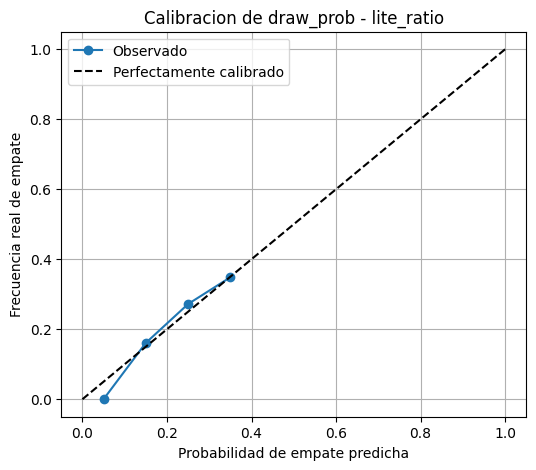

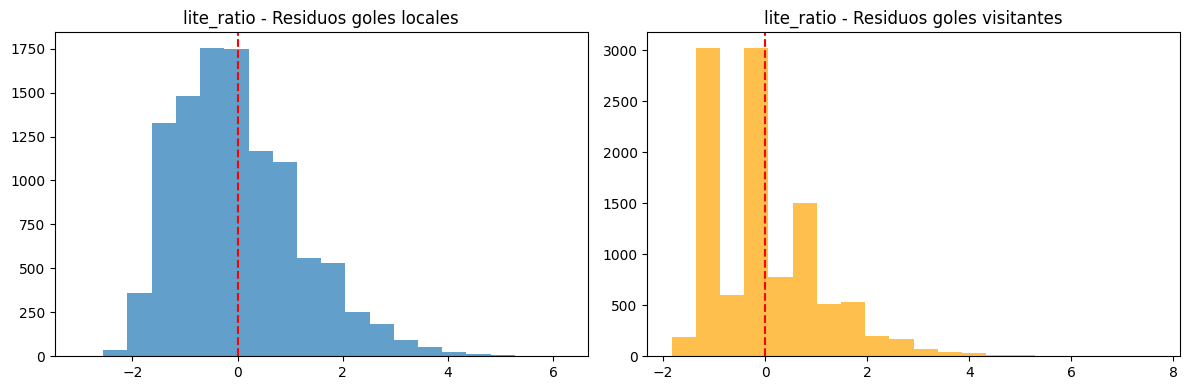

Residuos home - media: 0.004, std: 1.180
Residuos away - media: 0.012, std: 1.071


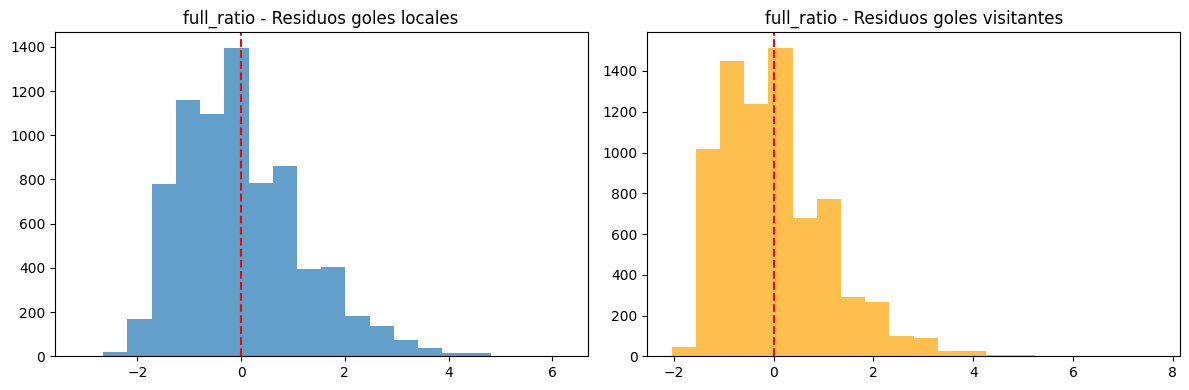

Residuos home - media: 0.008, std: 1.192
Residuos away - media: 0.018, std: 1.083


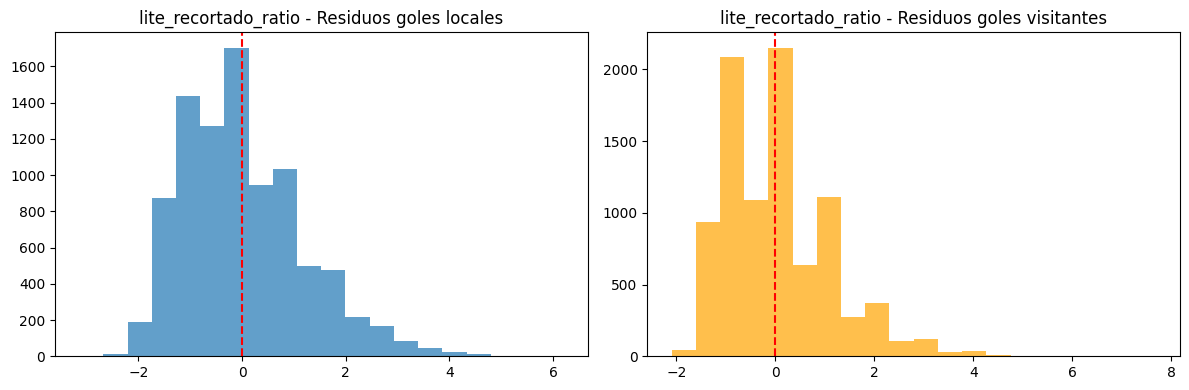

Residuos home - media: 0.009, std: 1.182
Residuos away - media: 0.024, std: 1.075


In [17]:
# === Skellam/LGBM (entrenamientos, calibracion y graficos) ===

# Controles globales (se comparten con el resto de bloques)
if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "RUN_SANITY_CHECK" not in globals():
    RUN_SANITY_CHECK = True
if "FAST_MODE" not in globals():
    FAST_MODE = True
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False
if "DEBUG_MODE" not in globals():
    DEBUG_MODE = False
if "PARALLEL_SKELLAM" not in globals():
    PARALLEL_SKELLAM = False
if "N_JOBS" not in globals():
    _cpu = os.cpu_count() or 2
    N_JOBS = max(1, _cpu - 1)

# Skellam/LGBM siempre se ejecuta para generar dataset_draw_ratio
# (en sanity/debug se usa el dataset truncado a 100 filas)
RUN_SKELLAM_LGBM = True

# Datasets por split
datasets = {
    "lite": {
        "ratio": (train_df_lite_ratio, test_df_lite_ratio),
        "year": (train_df_lite_year, test_df_lite_year),
    },
    "full": {
        "ratio": (train_df_full_ratio, test_df_full_ratio),
        "year": (train_df_full_year, test_df_full_year),
    },
    "lite_recortado": {
        "ratio": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
        "year": (train_df_lite_recortado_year, test_df_lite_recortado_year),
    },
}

dataset_frames = {
    "lite": df_lite,
    "full": df_full,
    "lite_recortado": df_lite_recortado,
}

dataset_draw_ratio = None
skellam_results = None

# Parametros de entrenamiento
if FAST_MODE:
    LGBM_N_ESTIMATORS = 80
    LGBM_LR = 0.08
    LGBM_MAX_DEPTH = 4
    LGBM_EARLY_STOP = 5
    LGBM_LOG_EVAL = 100
else:
    LGBM_N_ESTIMATORS = 200
    LGBM_LR = 0.05
    LGBM_MAX_DEPTH = 5
    LGBM_EARLY_STOP = 10
    LGBM_LOG_EVAL = 50

def _skellam_job(dataset_name, split_name, train_df, test_df):
    feature_cols = get_rolling_features(train_df)
    model_prefix = f"{dataset_name}_{split_name}"
    df_with_draw, model_home, model_away = train_lgbm_and_add_draw_prob(
        train_df,
        test_df,
        model_prefix,
        feature_cols,
        n_estimators=LGBM_N_ESTIMATORS,
        learning_rate=LGBM_LR,
        max_depth=LGBM_MAX_DEPTH,
        early_stopping_rounds=LGBM_EARLY_STOP,
        log_eval=LGBM_LOG_EVAL,
    )
    return dataset_name, split_name, df_with_draw, model_home, model_away

if RUN_SKELLAM_LGBM:
    skellam_results = {}
    if PARALLEL_SKELLAM:
        jobs = []
        for dataset_name, splits in datasets.items():
            for split_name, (train_df, test_df) in splits.items():
                jobs.append((dataset_name, split_name, train_df, test_df))
        results = joblib.Parallel(n_jobs=N_JOBS)(
            joblib.delayed(_skellam_job)(dataset_name, split_name, train_df, test_df)
            for dataset_name, split_name, train_df, test_df in jobs
        )
        for dataset_name, split_name, df_with_draw, model_home, model_away in results:
            skellam_results[(dataset_name, split_name)] = {
                "df_with_draw": df_with_draw,
                "model_home": model_home,
                "model_away": model_away,
            }
    else:
        for dataset_name, splits in datasets.items():
            for split_name, (train_df, test_df) in splits.items():
                feature_cols = get_rolling_features(train_df)
                model_prefix = f"{dataset_name}_{split_name}"
                df_with_draw, model_home, model_away = train_lgbm_and_add_draw_prob(
                    train_df,
                    test_df,
                    model_prefix,
                    feature_cols,
                    n_estimators=LGBM_N_ESTIMATORS,
                    learning_rate=LGBM_LR,
                    max_depth=LGBM_MAX_DEPTH,
                    early_stopping_rounds=LGBM_EARLY_STOP,
                    log_eval=LGBM_LOG_EVAL,
                )
                skellam_results[(dataset_name, split_name)] = {
                    "df_with_draw": df_with_draw,
                    "model_home": model_home,
                    "model_away": model_away,
                }

    # Accesos directos (opcional)
    df_lite_with_draw_ratio = skellam_results[("lite", "ratio")]["df_with_draw"]
    df_lite_with_draw_year = skellam_results[('lite', 'year')]["df_with_draw"]
    df_full_with_draw_ratio = skellam_results[("full", "ratio")]["df_with_draw"]
    df_full_with_draw_year = skellam_results[('full', 'year')]["df_with_draw"]
    df_lite_recortado_with_draw_ratio = skellam_results[("lite_recortado", "ratio")]["df_with_draw"]
    df_lite_recortado_with_draw_year = skellam_results[('lite_recortado', 'year')]["df_with_draw"]

    # --- Skellam/LGBM (resumen draw_prob) ---
    eval_targets = [
        ("lite", "ratio"), ("lite", "year"),
        ("full", "ratio"), ("full", "year"),
        ("lite_recortado", "ratio"), ("lite_recortado", "year"),
    ]
    for dataset_name, split_name in eval_targets:
        df_with_draw = skellam_results[(dataset_name, split_name)]["df_with_draw"]
        desc = df_with_draw["draw_prob"].describe()
        print(f"\n[{dataset_name}/{split_name}] draw_prob stats:")
        print(desc)

    # Checkpoint: guardamos copias con draw_prob (ratio)
    ruta_lite_out = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_with_draw_ratio.csv"
    ruta_full_out = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_with_draw_ratio.csv"
    df_lite_with_draw_ratio.to_csv(ruta_lite_out, index=False)
    df_full_with_draw_ratio.to_csv(ruta_full_out, index=False)
    print(f"Lite guardado en: {ruta_lite_out}")
    print(f"Full guardado en: {ruta_full_out}")

    # Vista rapida de draw_prob
    print("Lite (ratio) - draw_prob (primeros 5):")
    print(df_lite_with_draw_ratio[["home_goals", "away_goals", "draw_prob"]].head())
    print("\nFull (ratio) - draw_prob (primeros 5):")
    print(df_full_with_draw_ratio[["home_goals", "away_goals", "draw_prob"]].head())

    # --- Skellam/LGBM (evaluacion MAE + logloss) ---
    metrics_skellam = {}
    for dataset_name, split_name in eval_targets:
        train_df, test_df = datasets[dataset_name][split_name]
        feature_cols = get_rolling_features(train_df)
        model_home = skellam_results[(dataset_name, split_name)]["model_home"]
        model_away = skellam_results[(dataset_name, split_name)]["model_away"]
        metrics_skellam[(dataset_name, split_name)] = evaluate_model(
            train_df, test_df, model_home, model_away, feature_cols, f"{dataset_name}_{split_name}"
        )

    # Calibracion (ejemplo con lite/ratio)
    dataset_name = "lite"
    split_name = "ratio"
    train_df, test_df = datasets[dataset_name][split_name]
    feature_cols = get_rolling_features(train_df)
    model_home = skellam_results[(dataset_name, split_name)]["model_home"]
    model_away = skellam_results[(dataset_name, split_name)]["model_away"]
    plot_calibration(test_df, model_home, model_away, feature_cols, f"{dataset_name}_{split_name}")

    # Residuos (ejemplo con lite/full ratio)
    for dataset_name in ["lite", "full", "lite_recortado"]: # Only iterate for 'lite'
        split_name = "ratio"
        train_df, test_df = datasets[dataset_name][split_name]
        feature_cols = get_rolling_features(train_df)
        model_home = skellam_results[(dataset_name, split_name)]["model_home"]
        model_away = skellam_results[(dataset_name, split_name)]["model_away"]
        plot_residuals(test_df, model_home, model_away, feature_cols, f"{dataset_name}_{split_name}")

    dataset_draw_ratio = {
        "lite": df_lite_with_draw_ratio,
        "full": df_full_with_draw_ratio,
        "lite_recortado": df_lite_recortado_with_draw_ratio,
    }
    df_lite_reentrenado = df_lite_with_draw_ratio
    df_full_reentrenado = df_full_with_draw_ratio
    df_lite_recortado_reentrenado = df_lite_recortado_with_draw_ratio
else:
    if all(name in globals() for name in ["df_lite_reentrenado", "df_full_reentrenado", "df_lite_recortado_reentrenado"]):
        dataset_draw_ratio = {
            "lite": df_lite_reentrenado,
            "full": df_full_reentrenado,
            "lite_recortado": df_lite_recortado_reentrenado,
        }
    else:
        dataset_draw_ratio = None


In [18]:
# Otra version del septimo entrenamiento

# 1. DEFINICION DE FEATURES (Contexto Puro + Ventaja Dinamica)
# Eliminamos los rankings mu_home/away de aqui para que Glicko los maneje por su cuenta
feature_cols = [
    'diff_MarketValue',
    'diff_NetSpending',
    'diff_temperature_2m',
    'diff_PiO2',
    'diff_Foreign',
    'home_OccRat'
]

# 2. PREPARACION Y ESTANDARIZACION
if 'dataset_draw_ratio' not in globals() or dataset_draw_ratio is None:
    raise ValueError(
        'Falta dataset_draw_ratio. Ejecuta Skellam/LGBM (RUN_FULL_TRAINING=True) antes de este bloque.'
    )

# 3. FUNCION OBJETIVO CON CONTROL DE SOBREAJUSTE
def objective_glicko_shelopugin(beta_params, df, cols, burn_in, l2_lambda=0.01):
    """
    beta_params: [intercept, beta1, ..., betaN]
    l2_lambda: Parametro de regularizacion para evitar sobreajuste.
    """
    equipos = pd.concat([df['home_team'], df['away_team']]).unique()
    ratings = {eq: RatingG2A() for eq in equipos}

    model = Glicko2G2A(n_features=len(cols))
    model.set_beta(beta_params)

    total_loss = 0.0
    count = 0

    for i, row in df.iterrows():
        home, away = row['home_team'], row['away_team']
        feats = [row[c] for c in cols]
        skellam = row['draw_prob']

        # Probabilidades actuales (antes de actualizar el rating con el resultado)
        p_win, p_tie, p_loss = model.probabilities(
            ratings[home], ratings[away],
            features=feats,
            skellam_draw_probability=skellam
        )

        if i >= burn_in:
            if row['home_goals'] > row['away_goals']:
                prob = p_win
            elif row['home_goals'] < row['away_goals']:
                prob = p_loss
            else:
                prob = p_tie

            # Clip para estabilidad numerica
            total_loss -= np.log(np.clip(prob, 0.01, 0.99))
            count += 1

        # Actualizacion de Ratings (Aprendizaje del modelo)
        out = 'H' if row['home_goals'] > row['away_goals'] else ('A' if row['home_goals'] < row['away_goals'] else 'D')
        ratings[home], ratings[away] = model.rate(
            ratings[home], ratings[away],
            out,
            features=feats,
            skellam_draw_probability=skellam
        )

    # LogLoss base
    if count == 0:
        # Sin muestras evaluadas (burn_in demasiado alto); devolvemos penalizacion grande
        return 1e6 + l2_lambda * np.sum(np.square(beta_params[1:]))
    base_loss = total_loss / count

    # PENALIZACION L2: Evita que los Betas crezcan sin control (Sobreajuste)
    # No penalizamos el intercepto (beta[0])
    reg_term = l2_lambda * np.sum(np.square(beta_params[1:]))

    return base_loss + reg_term

# 4. EJECUCION DE LA OPTIMIZACION (por dataset)
# [Intercepto, 6 features] = 7 parametros
initial_beta = [0.0] * (len(feature_cols) + 1)
burn_in_val = 1000
results_shelopugin = {}

for dataset_name, df_input in dataset_draw_ratio.items():
    df_input = df_input.copy().sort_values('match_id_new').reset_index(drop=True)
    burn_in_use = min(burn_in_val, max(len(df_input) - 1, 0))

    # Estandarizamos todas las features para que la regularizacion L2 sea equitativa
    scaler_stats = {}
    for col in feature_cols:
        mean, std = df_input[col].mean(), df_input[col].std()
        df_input[col] = (df_input[col] - mean) / (std + 1e-8)
        scaler_stats[col] = (mean, std)

    print(f"\n[{dataset_name}] Optimizando modelo G2S (Shelopugin-Sirotkin) con {len(feature_cols)} features...")
    print("Control de sobreajuste activo (L2 Regularization).")

    res = minimize(
        objective_glicko_shelopugin,
        initial_beta,
        args=(df_input, feature_cols, burn_in_use, 0.01),  # l2_lambda=0.01
        method='L-BFGS-B',
        options={'disp': True, 'maxiter': 80}
    )

    # 5. RESULTADOS
    print("-" * 50)
    logloss_final = res.fun - (0.01 * np.sum(np.square(res.x[1:])))
    print(f"LogLoss Final (Sin penalidad): {logloss_final:.6f}")

    print("\nCoeficientes de la Ecuacion de Ventaja:")
    nombres = ['Intercepto'] + feature_cols
    for nom, val in zip(nombres, res.x):
        print(f"  {nom.ljust(25)}: {val:.5f}")

    results_shelopugin[dataset_name] = {
        'res': res,
        'scaler_stats': scaler_stats,
        'logloss_final': logloss_final,
        'coef': dict(zip(nombres, res.x)),
    }


[lite] Optimizando modelo G2S (Shelopugin-Sirotkin) con 6 features...
Control de sobreajuste activo (L2 Regularization).


/tmp/ipykernel_5091/3180710665.py:100: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


--------------------------------------------------
LogLoss Final (Sin penalidad): 1.100951

Coeficientes de la Ecuacion de Ventaja:
  Intercepto               : 2.51642
  diff_MarketValue         : 0.00132
  diff_NetSpending         : -0.00174
  diff_temperature_2m      : 0.00096
  diff_PiO2                : 0.00067
  diff_Foreign             : -0.00300
  home_OccRat              : -0.00476

[full] Optimizando modelo G2S (Shelopugin-Sirotkin) con 6 features...
Control de sobreajuste activo (L2 Regularization).


/tmp/ipykernel_5091/3180710665.py:100: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


--------------------------------------------------
LogLoss Final (Sin penalidad): 1.099064

Coeficientes de la Ecuacion de Ventaja:
  Intercepto               : 2.31306
  diff_MarketValue         : 0.00186
  diff_NetSpending         : -0.00014
  diff_temperature_2m      : 0.00033
  diff_PiO2                : 0.00019
  diff_Foreign             : -0.00199
  home_OccRat              : -0.00066

[lite_recortado] Optimizando modelo G2S (Shelopugin-Sirotkin) con 6 features...
Control de sobreajuste activo (L2 Regularization).


/tmp/ipykernel_5091/3180710665.py:100: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


--------------------------------------------------
LogLoss Final (Sin penalidad): 1.102812

Coeficientes de la Ecuacion de Ventaja:
  Intercepto               : 1.77415
  diff_MarketValue         : 0.00153
  diff_NetSpending         : -0.00077
  diff_temperature_2m      : -0.00085
  diff_PiO2                : 0.00085
  diff_Foreign             : -0.00188
  home_OccRat              : -0.00109


In [ ]:
# Otra version del Octavo entrenamiento con los parametros iniciales ajustados para que la convergencia sea mas rapida (G2Av1513)

# -------------------------------
# Configuracion general
# -------------------------------
if 'dataset_draw_ratio' not in globals() or dataset_draw_ratio is None:
    raise ValueError('Falta dataset_draw_ratio. Ejecuta Skellam/LGBM antes de este bloque.')
league_col = "Competition"
pandemic_col = None  # Ej: "pandemic" si existe
use_pandemic = False
train_ratio = 0.7
min_prob = 1e-15
rd_init = 80.0
vol_init = 0.06
mu_global_init = 1500.0
l2_lambda = 0.0
log_every = 1  # imprime cada N evaluaciones del optimizador

# Bounds (ajustables)
draw_bounds = (-5.0, 5.0)
mu_init_scaled_bounds = (-300.0, 300.0)
h_scaled_bounds = (0.0, 20.0)
h_p_scaled_bounds = (0.0, 20.0)

# -------------------------------
# Utils
# -------------------------------
def chronological_split(df, ratio=0.7, date_col="match_date_from_id"):
    if date_col in df.columns:
        df_sorted = df.sort_values(date_col).reset_index(drop=True)
    else:
        df_sorted = df.reset_index(drop=True)
    n_train = int(len(df_sorted) * ratio)
    train_df = df_sorted.iloc[:n_train].copy()
    test_df = df_sorted.iloc[n_train:].copy()
    return train_df, test_df

def outcome_from_row(row):
    if row["home_goals"] > row["away_goals"]:
        return "H"
    if row["home_goals"] < row["away_goals"]:
        return "A"
    return "D"

def init_rating(mu_init):
    return RatingG2A(mu=mu_init, rd=rd_init, volatility=vol_init)

def build_league_index(df, league_col):
    leagues = sorted(df[league_col].dropna().unique().tolist())
    idx = {lg: i for i, lg in enumerate(leagues)}
    return leagues, idx

def unpack_params(x, n_leagues, use_pandemic_flag):
    d = x[0]
    mu_scaled = x[1:1 + n_leagues]
    h_scaled = x[1 + n_leagues:1 + 2 * n_leagues]
    # Reconstruccion a valores reales
    mu_inits = mu_global_init + mu_scaled    # ej: 0 -> 1500, -200 -> 1300
    h_vals = h_scaled * 10.0                 # ej: 5 -> 50, 20 -> 200
    h_p_vals = None
    if use_pandemic_flag:
        h_p_scaled = x[1 + 2 * n_leagues:1 + 3 * n_leagues]
        h_p_vals = h_p_scaled * 10.0
    return d, mu_inits, h_vals, h_p_vals

def make_bounds(n_leagues, use_pandemic_flag):
    bounds = [draw_bounds]
    bounds += [mu_init_scaled_bounds] * n_leagues
    bounds += [h_scaled_bounds] * n_leagues
    if use_pandemic_flag:
        bounds += [h_scaled_bounds] * n_leagues
    return bounds

# -------------------------------
# Objective
# -------------------------------
eval_counter = {"n": 0}

def objective_factory(train_df, leagues, league_index, use_pandemic_flag):
    def objective(x):
        eval_counter["n"] += 1
        d, mu_inits, h_vals, h_p_vals = unpack_params(x, len(leagues), use_pandemic_flag)
        mu_map = {lg: mu_inits[league_index[lg]] for lg in leagues}
        h_map = {lg: h_vals[league_index[lg]] for lg in leagues}
        h_p_map = {lg: h_p_vals[league_index[lg]] for lg in leagues} if use_pandemic_flag else {}
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])

        ratings = {}
        loss = 0.0
        count = 0
        for _, row in train_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = float(np.clip(row["draw_prob"], 1e-12, 1.0 - 1e-12))
            out = outcome_from_row(row)

            if home not in ratings:
                ratings[home] = init_rating(mu_map[league])
            if away not in ratings:
                ratings[away] = init_rating(mu_map[league])

            pandemic_flag = False
            if use_pandemic_flag and pandemic_col in train_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            home_adv = h_map[league]
            home_pandemic_adv = h_p_map.get(league) if use_pandemic_flag else None
            adv_feat = home_pandemic_adv if (use_pandemic_flag and pandemic_flag and home_pandemic_adv is not None) else home_adv
            pw, pd_, pl = model.probabilities(
                ratings[home],
                ratings[away],
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            p_actual = pw if out == "H" else (pl if out == "A" else pd_)
            loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            count += 1
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )

        if eval_counter["n"] % 20 == 0 and ratings:
            mus = [r.mu for r in ratings.values()]
            print(f"   ratings min={min(mus):.1f} max={max(mus):.1f} rango={max(mus)-min(mus):.1f}", flush=True)

        avg_loss = loss / max(count, 1)
        l2 = (d ** 2)
        l2 += np.sum((mu_inits - mu_global_init) ** 2)
        l2 += np.sum(h_vals ** 2)
        if use_pandemic_flag and h_p_vals is not None:
            l2 += np.sum(h_p_vals ** 2)
            l2 += np.sum(np.maximum(0.0, h_p_vals - h_vals) ** 2) * 1000.0
        avg_loss += l2_lambda * l2

        if eval_counter["n"] % log_every == 0:
            print(f"Eval {eval_counter['n']}: loss={avg_loss:.6f}, d={d:.4f}")
        return avg_loss
    return objective

# -------------------------------
# Train/eval runner + export
# -------------------------------
def run_pipeline(df, tag):
    if use_pandemic and pandemic_col is None:
        raise ValueError("Define pandemic_col si use_pandemic=True")
    train_df, test_df = chronological_split(df, ratio=train_ratio)
    leagues, league_index = build_league_index(train_df, league_col)
    bounds = make_bounds(len(leagues), use_pandemic)

    x0 = []
    x0.append(0.5)                     # d
    x0 += [0.0] * len(leagues)        # mu escalados a 0 (->1500)
    x0 += [5.0] * len(leagues)        # h escalados a 5 (->50)
    if use_pandemic:
        x0 += [3.0] * len(leagues)
    x0 = np.asarray(x0, dtype=float)

    objective = objective_factory(train_df, leagues, league_index, use_pandemic)
    res = minimize(
        objective,
        x0,
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": 400, "disp": True},
    )

    d, mu_inits, h_vals, h_p_vals = unpack_params(res.x, len(leagues), use_pandemic)
    mu_map = {lg: float(mu_inits[league_index[lg]]) for lg in leagues}
    h_map = {lg: float(h_vals[league_index[lg]]) for lg in leagues}
    h_p_map = {lg: float(h_p_vals[league_index[lg]]) for lg in leagues} if use_pandemic else {}

    def _get_mu_h(league):
        mu = mu_map.get(league, mu_global_init)
        h = h_map.get(league, 0.0)
        h_p = h_p_map.get(league) if use_pandemic else None
        return mu, h, h_p

    # Evaluate on test (train first, then test)
    model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
    model.set_beta([0.0, 1.0])
    ratings = {}
    for _, row in train_df.iterrows():
        league = row[league_col]
        home = row["home_team"]
        away = row["away_team"]
        s_prob = float(np.clip(row["draw_prob"], 1e-12, 1.0 - 1e-12))
        out = outcome_from_row(row)
        if home not in ratings:
            mu_init, _, _ = _get_mu_h(league)
            ratings[home] = init_rating(mu_init)
        if away not in ratings:
            mu_init, _, _ = _get_mu_h(league)
            ratings[away] = init_rating(mu_init)
        pandemic_flag = False
        if use_pandemic and pandemic_col in train_df.columns:
            pandemic_flag = bool(row[pandemic_col])
        _, home_adv, home_pandemic_adv = _get_mu_h(league)
        adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
        ratings[home], ratings[away] = model.rate(
            ratings[home],
            ratings[away],
            outcome=out,
            features=[adv_feat],
            skellam_draw_probability=s_prob,
        )

    test_loss = 0.0
    y_true_bin = []
    y_pred_bin = []
    for _, row in test_df.iterrows():
        league = row[league_col]
        home = row["home_team"]
        away = row["away_team"]
        s_prob = float(np.clip(row["draw_prob"], 1e-12, 1.0 - 1e-12))
        out = outcome_from_row(row)
        if home not in ratings:
            mu_init, _, _ = _get_mu_h(league)
            ratings[home] = init_rating(mu_init)
        if away not in ratings:
            mu_init, _, _ = _get_mu_h(league)
            ratings[away] = init_rating(mu_init)
        pandemic_flag = False
        if use_pandemic and pandemic_col in test_df.columns:
            pandemic_flag = bool(row[pandemic_col])
        _, home_adv, home_pandemic_adv = _get_mu_h(league)
        adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
        pw, pd_, pl = model.probabilities(
            ratings[home],
            ratings[away],
            features=[adv_feat],
            skellam_draw_probability=s_prob,
        )
        p_actual = pw if out == "H" else (pl if out == "A" else pd_)
        y_true_bin.append(1 if out == "H" else 0)
        y_pred_bin.append(float(pw))
        test_loss -= np.log(np.clip(p_actual, min_prob, 1.0))
        ratings[home], ratings[away] = model.rate(
            ratings[home],
            ratings[away],
            outcome=out,
            features=[adv_feat],
            skellam_draw_probability=s_prob,
        )
    test_loss /= max(len(test_df), 1)
    print(f"Test logloss: {test_loss:.6f}")
    ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
    print(f"Test logloss binario (local gana vs no gana): {ll_bin:.6f}")

    # Export params
    params_out = {
        "draw_adjustment": float(d),
        "mu_init_by_league": mu_map,
        "h_by_league": h_map,
        "h_p_by_league": h_p_map,
    }
    params_path = f"glicko_params_{tag}.json"
    with open(params_path, "w", encoding="utf-8") as f:
        json.dump(params_out, f, indent=2)
    print(f"Parametros guardados en {params_path}")

    # Export ratings history after each match
    full_df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)
    ratings = {}
    history = []
    model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
    model.set_beta([0.0, 1.0])
    for idx, row in full_df.iterrows():
        league = row[league_col]
        home = row["home_team"]
        away = row["away_team"]
        s_prob = float(np.clip(row["draw_prob"], 1e-12, 1.0 - 1e-12))
        out = outcome_from_row(row)
        if home not in ratings:
            mu_init, _, _ = _get_mu_h(league)
            ratings[home] = init_rating(mu_init)
        if away not in ratings:
            mu_init, _, _ = _get_mu_h(league)
            ratings[away] = init_rating(mu_init)
        pandemic_flag = False
        if use_pandemic and pandemic_col in full_df.columns:
            pandemic_flag = bool(row[pandemic_col])
        _, home_adv, home_pandemic_adv = _get_mu_h(league)
        adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
        ratings[home], ratings[away] = model.rate(
            ratings[home],
            ratings[away],
            outcome=out,
            features=[adv_feat],
            skellam_draw_probability=s_prob,
        )
        match_id = row["match_id_new"] if "match_id_new" in full_df.columns else idx
        history.append({
            "match_id": match_id,
            "league": league,
            "home_team": home,
            "away_team": away,
            "home_mu": ratings[home].mu,
            "away_mu": ratings[away].mu,
            "home_rd": ratings[home].rd,
            "away_rd": ratings[away].rd,
        })
    ratings_hist_path = f"glicko_ratings_history_{tag}.csv"
    pd.DataFrame(history).to_csv(ratings_hist_path, index=False)
    print(f"Ratings guardados en {ratings_hist_path}")

    final_ratings = [
        {"team": team, "mu": r.mu, "rd": r.rd, "volatility": r.volatility}
        for team, r in ratings.items()
    ]
    ratings_final_path = f"glicko_ratings_final_{tag}.csv"
    pd.DataFrame(final_ratings).to_csv(ratings_final_path, index=False)
    print(f"Ratings finales guardados en {ratings_final_path}")

    return res, params_out

# Ejecutar por dataset
pipeline_results = {}
for dataset_name, df_model in dataset_draw_ratio.items():
    print(f"\n[Pipeline G2Av1513] dataset={dataset_name}")
    result, params = run_pipeline(df_model, dataset_name)
    pipeline_results[dataset_name] = {"result": result, "params": params}


[Pipeline G2Av1513] dataset=lite


/tmp/ipykernel_485/700347045.py:164: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Eval 1: loss=1.075251, d=0.5000
Eval 2: loss=1.075251, d=0.5000
Eval 3: loss=1.075251, d=0.5000
Eval 4: loss=1.075251, d=0.5000
Eval 5: loss=1.075251, d=0.5000
Eval 6: loss=1.075251, d=0.5000
Eval 7: loss=1.075251, d=0.5000
Eval 8: loss=1.075251, d=0.5000
Eval 9: loss=1.075251, d=0.5000
Eval 10: loss=1.075251, d=0.5000
Eval 11: loss=1.075251, d=0.5000
Eval 12: loss=1.075251, d=0.5000
Eval 13: loss=1.075251, d=0.5000
Eval 14: loss=1.075251, d=0.5000
Eval 15: loss=1.075251, d=0.5000
Eval 16: loss=1.075251, d=0.5000
Eval 17: loss=1.075251, d=0.5000
Eval 18: loss=1.075251, d=0.5000
Eval 19: loss=1.075251, d=0.5000
   ratings min=1274.6 max=1805.8 rango=531.2
Eval 20: loss=1.075251, d=0.5000
Eval 21: loss=1.075251, d=0.5000
Eval 22: loss=1.075251, d=0.5000
Eval 23: loss=1.075251, d=0.5000
Eval 24: loss=1.075251, d=0.5000
Eval 25: loss=1.075251, d=0.5000
Eval 26: loss=1.075251, d=0.5000
Eval 27: loss=1.075251, d=0.5000
Eval 28: loss=1.075251, d=0.5000
Eval 29: loss=1.075251, d=0.5000
Eval 30

KeyboardInterrupt: 

In [19]:
# === RRNN (entrenamiento separado) ===

if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "FAST_MODE" not in globals():
    FAST_MODE = True
if "EXHAUSTIVE_MODE" not in globals():
    EXHAUSTIVE_MODE = False

RUN_RRNN = True
if not RUN_FULL_TRAINING and not DEBUG_MODE:
    RUN_RRNN = False

if RUN_RRNN:
    if dataset_draw_ratio is None:
        print("RRNN omitido: dataset_draw_ratio no disponible")
    elif torch is None:
        print("PyTorch no disponible: se omite RRNN")
    else:
        for dataset_name, df_rrnn in dataset_draw_ratio.items():
            print(f"\n[RRNN] dataset={dataset_name}")
            df_rrnn = df_rrnn.copy()
            if EXHAUSTIVE_MODE:
                seq_len = 10
                train_ratio = 0.7
                val_ratio = 0.1
                batch_size = 256
                epochs = 60
                lr = 8e-4
                weight_decay = 1e-4
                hidden_size = 128
                dropout = 0.2
            elif FAST_MODE:
                seq_len = 6
                train_ratio = 0.7
                val_ratio = 0.08
                batch_size = 256
                epochs = 8
                lr = 1e-3
                weight_decay = 1e-4
                hidden_size = 48
                dropout = 0.2
            else:
                seq_len = 8
                train_ratio = 0.7
                val_ratio = 0.1
                batch_size = 256
                epochs = 30
                lr = 1e-3
                weight_decay = 1e-4
                hidden_size = 64
                dropout = 0.2
            min_prob = 1e-15
            seed = 42

            rng = np.random.default_rng(seed)
            torch.manual_seed(seed)

            exclude_cols = [
                "match_id_new", "match_date_from_id", "Competition",
                "home_team", "away_team", "home_team_id", "away_team_id",
                "home_goals", "away_goals", "home_Goals", "away_Goals",
                "year_from_id", "month_from_id",
                "mu_home", "mu_away",
            ]
            numeric_cols = [c for c in df_rrnn.columns if pd.api.types.is_numeric_dtype(df_rrnn[c])]
            feature_cols = [c for c in numeric_cols if c not in exclude_cols]
            if "draw_prob" not in feature_cols and "draw_prob" in df_rrnn.columns:
                feature_cols.append("draw_prob")

            df_rrnn = df_rrnn.sort_values("match_date_from_id").reset_index(drop=True)
            df_rrnn[feature_cols] = df_rrnn[feature_cols].fillna(0.0)

            hist_extra_cols = ["is_home", "goals_for", "goals_against", "result"]
            base_dim = len(feature_cols)
            extra_dim = len(hist_extra_cols)
            hist_dim = base_dim + extra_dim

            def outcome_label(row):
                if row["home_goals"] > row["away_goals"]:
                    return 0  # Home win
                if row["home_goals"] < row["away_goals"]:
                    return 2  # Away win
                return 1  # Draw

            def build_hist_vec(row, side):
                is_home = 1.0 if side == "home" else 0.0
                goals_for = float(row["home_goals"] if side == "home" else row["away_goals"])
                goals_against = float(row["away_goals"] if side == "home" else row["home_goals"])
                if goals_for > goals_against:
                    result = 1.0
                elif goals_for < goals_against:
                    result = -1.0
                else:
                    result = 0.0
                base = [float(row[c]) for c in feature_cols]
                return np.array(base + [is_home, goals_for, goals_against, result], dtype=np.float32)

            team_hist = {}
            samples = []

            for idx, row in df_rrnn.iterrows():
                home = row["home_team"]
                away = row["away_team"]
                home_hist = team_hist.get(home, [])
                away_hist = team_hist.get(away, [])

                def pad_seq(seq):
                    if len(seq) >= seq_len:
                        return np.stack(seq[-seq_len:], axis=0)
                    pad = [np.zeros(hist_dim, dtype=np.float32) for _ in range(seq_len - len(seq))]
                    return np.stack(pad + seq, axis=0)

                home_seq = pad_seq(home_hist)
                away_seq = pad_seq(away_hist)
                cur_feat = np.array([float(row[c]) for c in feature_cols], dtype=np.float32)
                label = outcome_label(row)
                samples.append({
                    "idx": idx,
                    "home_seq": home_seq,
                    "away_seq": away_seq,
                    "cur_feat": cur_feat,
                    "label": label,
                })

                team_hist.setdefault(home, []).append(build_hist_vec(row, "home"))
                team_hist.setdefault(away, []).append(build_hist_vec(row, "away"))

            n_total = len(samples)
            n_train = int(n_total * train_ratio)
            n_val = int(n_train * val_ratio)
            train_samples = samples[: n_train - n_val]
            val_samples = samples[n_train - n_val : n_train]
            test_samples = samples[n_train :]

            def stack_base(samples_list):
                cur = np.stack([s["cur_feat"] for s in samples_list], axis=0)
                hist = np.stack([s["home_seq"] for s in samples_list] + [s["away_seq"] for s in samples_list], axis=0)
                hist_base = hist[:, :, :base_dim].reshape(-1, base_dim)
                return cur, hist_base

            cur_train, hist_base_train = stack_base(train_samples)
            base_scaler = StandardScaler().fit(np.vstack([cur_train, hist_base_train]))
            extra_scaler = StandardScaler().fit(
                np.stack([s["home_seq"] for s in train_samples], axis=0)[:, :, base_dim:].reshape(-1, extra_dim)
            )

            def apply_scaling(samples_list):
                for s in samples_list:
                    s["cur_feat"] = base_scaler.transform(s["cur_feat"].reshape(1, -1)).reshape(-1)
                    h_base = base_scaler.transform(s["home_seq"][:, :base_dim])
                    h_extra = extra_scaler.transform(s["home_seq"][:, base_dim:])
                    s["home_seq"] = np.concatenate([h_base, h_extra], axis=1)
                    a_base = base_scaler.transform(s["away_seq"][:, :base_dim])
                    a_extra = extra_scaler.transform(s["away_seq"][:, base_dim:])
                    s["away_seq"] = np.concatenate([a_base, a_extra], axis=1)

            apply_scaling(train_samples)
            apply_scaling(val_samples)
            apply_scaling(test_samples)

            class MatchDataset(Dataset):
                def __init__(self, samples_list):
                    self.samples = samples_list
                def __len__(self):
                    return len(self.samples)
                def __getitem__(self, idx):
                    s = self.samples[idx]
                    return (
                        torch.tensor(s["home_seq"], dtype=torch.float32),
                        torch.tensor(s["away_seq"], dtype=torch.float32),
                        torch.tensor(s["cur_feat"], dtype=torch.float32),
                        torch.tensor(s["label"], dtype=torch.long),
                    )

            train_loader = DataLoader(MatchDataset(train_samples), batch_size=batch_size, shuffle=True)
            val_loader = DataLoader(MatchDataset(val_samples), batch_size=batch_size, shuffle=False)
            test_loader = DataLoader(MatchDataset(test_samples), batch_size=batch_size, shuffle=False)

            class RRNN(nn.Module):
                def __init__(self, hist_dim, cur_dim, hidden, dropout=0.2):
                    super().__init__()
                    self.rnn = nn.GRU(hist_dim, hidden, batch_first=True)
                    self.cur_proj = nn.Linear(cur_dim, hidden)
                    self.dropout = nn.Dropout(dropout)
                    self.head = nn.Sequential(
                        nn.Linear(hidden * 3, hidden),
                        nn.ReLU(),
                        nn.Dropout(dropout),
                        nn.Linear(hidden, 3),
                    )
                def forward(self, home_seq, away_seq, cur_feat):
                    _, h_home = self.rnn(home_seq)
                    _, h_away = self.rnn(away_seq)
                    h_home = h_home[-1]
                    h_away = h_away[-1]
                    h_cur = torch.relu(self.cur_proj(cur_feat))
                    x = torch.cat([h_home, h_away, h_cur], dim=1)
                    x = self.dropout(x)
                    return self.head(x)

            device = "cuda" if torch.cuda.is_available() else "cpu"
            model = RRNN(hist_dim=hist_dim, cur_dim=base_dim, hidden=hidden_size, dropout=dropout).to(device)
            optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
            criterion = nn.CrossEntropyLoss()
            use_amp = device == "cuda"
            scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

            def run_epoch(loader, train_mode):
                model.train() if train_mode else model.eval()
                total_loss = 0.0
                total = 0
                correct = 0
                for home_seq, away_seq, cur_feat, y in loader:
                    home_seq = home_seq.to(device)
                    away_seq = away_seq.to(device)
                    cur_feat = cur_feat.to(device)
                    y = y.to(device)
                    optimizer.zero_grad(set_to_none=True)
                    with torch.amp.autocast(device_type="cuda", enabled=use_amp):
                        logits = model(home_seq, away_seq, cur_feat)
                        loss = criterion(logits, y)
                    if train_mode:
                        scaler.scale(loss).backward()
                        scaler.step(optimizer)
                        scaler.update()
                    total_loss += loss.item() * y.size(0)
                    total += y.size(0)
                    preds = torch.argmax(logits, dim=1)
                    correct += (preds == y).sum().item()
                return total_loss / max(total, 1), correct / max(total, 1)

            for epoch in range(1, epochs + 1):
                train_loss, train_acc = run_epoch(train_loader, train_mode=True)
                val_loss, val_acc = run_epoch(val_loader, train_mode=False)
                print(f"Epoch {epoch:02d} | train loss={train_loss:.5f} acc={train_acc:.3f} | val loss={val_loss:.5f} acc={val_acc:.3f}")

            test_loss, test_acc = run_epoch(test_loader, train_mode=False)
            print(f"Test loss={test_loss:.5f} acc={test_acc:.3f}")
            y_true_bin = []
            y_pred_bin = []
            model.eval()
            with torch.no_grad():
                for home_seq, away_seq, cur_feat, y in test_loader:
                    home_seq = home_seq.to(device)
                    away_seq = away_seq.to(device)
                    cur_feat = cur_feat.to(device)
                    logits = model(home_seq, away_seq, cur_feat)
                    probs = torch.softmax(logits, dim=1)
                    y_true_bin.extend((y.cpu().numpy() == 0).astype(int).tolist())
                    y_pred_bin.extend(probs[:, 0].detach().cpu().numpy().tolist())
            ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
            print(f"Test logloss binario (local gana vs no gana): {ll_bin:.6f}")


[RRNN] dataset=lite
Epoch 01 | train loss=1.03648 acc=0.472 | val loss=1.01188 acc=0.509
Epoch 02 | train loss=1.02137 acc=0.486 | val loss=1.00435 acc=0.510
Epoch 03 | train loss=1.01575 acc=0.486 | val loss=1.00511 acc=0.516
Epoch 04 | train loss=1.01306 acc=0.489 | val loss=1.00538 acc=0.509
Epoch 05 | train loss=1.00708 acc=0.494 | val loss=1.00849 acc=0.507
Epoch 06 | train loss=1.00285 acc=0.497 | val loss=1.01009 acc=0.507
Epoch 07 | train loss=0.99797 acc=0.501 | val loss=1.01077 acc=0.503
Epoch 08 | train loss=0.99227 acc=0.505 | val loss=1.01303 acc=0.497
Epoch 09 | train loss=0.98783 acc=0.509 | val loss=1.01883 acc=0.503
Epoch 10 | train loss=0.98014 acc=0.517 | val loss=1.02270 acc=0.494
Epoch 11 | train loss=0.97395 acc=0.523 | val loss=1.02492 acc=0.488
Epoch 12 | train loss=0.96920 acc=0.524 | val loss=1.02651 acc=0.489
Epoch 13 | train loss=0.96037 acc=0.533 | val loss=1.03411 acc=0.496
Epoch 14 | train loss=0.95564 acc=0.539 | val loss=1.04188 acc=0.481
Epoch 15 | tr

In [20]:
# === Bloque FINAL (penultima celda): ejecucion de entrenamientos y evaluaciones ===
# Este bloque fue fragmentado en modulos para poder entrenar y corregir mas eficientemente

# Modulo 0: Parametros
# Control de ejecucion
if "RUN_FULL_TRAINING" not in globals():
    RUN_FULL_TRAINING = True
if "RUN_SANITY_CHECK" not in globals():
    RUN_SANITY_CHECK = True
if "FAST_MODE" not in globals():
    FAST_MODE = True

# RUN_POISSON = True
RUN_POISSON = False
RUN_GLICKO_SOCCER = True
# RUN_G2A_OPT = True
RUN_G2A_OPT = False
# RUN_G2A_SWEEPS = True
RUN_G2A_SWEEPS = False
RUN_G2A_EXTRA = True
RUN_G2AV1513 = True
# RUN_G2AV1513_POWELL = True
RUN_G2AV1513_POWELL = False
RUN_STAGE2 = True

if not RUN_FULL_TRAINING and not DEBUG_MODE:
    RUN_POISSON = False
    RUN_GLICKO_SOCCER = False
    RUN_G2A_OPT = False
    RUN_G2A_SWEEPS = False
    RUN_G2A_EXTRA = False
    RUN_G2AV1513 = False
    RUN_G2AV1513_POWELL = False
    RUN_STAGE2 = False

print("=== Bloque final: configuracion de ejecucion ===")
print(f"TRAINING_MODE={TRAINING_MODE} | DEBUG_MODE={DEBUG_MODE} | FAST_MODE={FAST_MODE} | RUN_FULL_TRAINING={RUN_FULL_TRAINING}")
print(f"RUN_POISSON={RUN_POISSON} | RUN_GLICKO_SOCCER={RUN_GLICKO_SOCCER} | RUN_G2A_OPT={RUN_G2A_OPT} | RUN_G2A_SWEEPS={RUN_G2A_SWEEPS}")
print(f"RUN_G2A_EXTRA={RUN_G2A_EXTRA} | RUN_G2AV1513={RUN_G2AV1513} | RUN_G2AV1513_POWELL={RUN_G2AV1513_POWELL} | RUN_STAGE2={RUN_STAGE2}")

# Fallbacks por si se ejecuta solo esta celda
if "datasets" not in globals():
    datasets = {
        "lite": {
            "ratio": (train_df_lite_ratio, test_df_lite_ratio),
            "year": (train_df_lite_year, test_df_lite_year),
        },
        "full": {
            "ratio": (train_df_full_ratio, test_df_full_ratio),
            "year": (train_df_full_year, test_df_full_year),
        },
        "lite_recortado": {
            "ratio": (train_df_lite_recortado_ratio, test_df_lite_recortado_ratio),
            "year": (train_df_lite_recortado_year, test_df_lite_recortado_year),
        },
    }
if "dataset_frames" not in globals():
    dataset_frames = {
        "lite": df_lite,
        "full": df_full,
        "lite_recortado": df_lite_recortado,
    }
if "dataset_draw_ratio" not in globals():
    dataset_draw_ratio = None

# Ajustes rapidos
if FAST_MODE:
    MAXITER_G2A = 120
    MAXITER_G2A_SWEEP = 120
    MAXITER_G2A_VARIANT = 120
    MAXITER_G2A_EXTRA = 30
    MAXITER_G2A_EXTRA2 = 40
    MAXITER_G2AV1513 = 200
    MAXITER_G2AV1513_POWELL = 120
    STAGE2_EPOCHS = 20
    GLICKO_LGBM_N_EST = 200
    GLICKO_LGBM_EARLY = 10
else:
    MAXITER_G2A = 250
    MAXITER_G2A_SWEEP = 250
    MAXITER_G2A_VARIANT = 250
    MAXITER_G2A_EXTRA = 50
    MAXITER_G2A_EXTRA2 = 60
    MAXITER_G2AV1513 = 400
    MAXITER_G2AV1513_POWELL = 200
    STAGE2_EPOCHS = 50
    GLICKO_LGBM_N_EST = 500
    GLICKO_LGBM_EARLY = 20


=== Bloque final: configuracion de ejecucion ===
TRAINING_MODE=deep | DEBUG_MODE=False | FAST_MODE=False | RUN_FULL_TRAINING=True
RUN_POISSON=False | RUN_GLICKO_SOCCER=True | RUN_G2A_OPT=False | RUN_G2A_SWEEPS=False
RUN_G2A_EXTRA=True | RUN_G2AV1513=True | RUN_G2AV1513_POWELL=False | RUN_STAGE2=True


In [21]:
# Modulo 1: Modelo Poisson Bivariante sin features
# --- Poisson bivariante (modelo sin features) ---
if RUN_POISSON:
    for dataset_name, df_model in dataset_frames.items():
        df_model = df_model.sort_values('match_date_from_id').reset_index(drop=True)
        n_train = int(0.7 * len(df_model))
        train = df_model.iloc[:n_train]
        test = df_model.iloc[n_train:]

        teams, team_to_idx, attack, defense, home_adv = train_poisson(train)

        y_true = []
        y_pred_poisson = []
        for _, row in test.iterrows():
            p_h, p_d, p_a = predict_poisson(
                row['home_team'], row['away_team'], teams, team_to_idx, attack, defense, home_adv
            )
            y_true.append(0 if row['home_goals'] > row['away_goals'] else (1 if row['home_goals'] == row['away_goals'] else 2))
            y_pred_poisson.append([p_h, p_d, p_a])

        ll_poisson = log_loss(y_true, y_pred_poisson, labels=[0, 1, 2])
        y_true_bin = (np.array(y_true) == 0).astype(int)
        ll_poisson_bin = log_loss(y_true_bin, np.array(y_pred_poisson)[:, 0], labels=[0, 1])
        print(f"[{dataset_name}] LogLoss Poisson bivariante: {ll_poisson:.6f}")
        print(f"[{dataset_name}] LogLoss binario (local gana vs no gana): {ll_poisson_bin:.6f}")



In [21]:
# Modulo 2: Modelo Glicko-2 Shelopugin Sirotkin con features
# --- Glicko2 baseline + boosting (modelo con features) ---
if RUN_GLICKO_SOCCER:
    for dataset_name, splits in datasets.items():
        df = dataset_frames[dataset_name].copy()
        train_df, test_df = splits['ratio']
        train_df = train_df.copy().sort_values('match_date_from_id').reset_index(drop=True)
        test_df = test_df.copy().sort_values('match_date_from_id').reset_index(drop=True)

        for d in [train_df, test_df]:
            d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')
            d['season'] = d['match_date_from_id'].dt.year
            country_map = {
                'PremierLeague': 'England', 'LaLiga': 'Spain', 'SerieA': 'Italy',
                'Bundesliga': 'Germany', 'Ligue1': 'France', 'SaudiProLeague': 'SaudiArabia',
                'MLS': 'USA', 'Brasileirao': 'Brazil', 'LigaArgentina': 'Argentina',
                'FutVe': 'Venezuela', 'J1League': 'Japan', 'KLeague1': 'SouthKorea',
                'LigaMX': 'Mexico', 'SuperLeagueGreece': 'Greece',
            }
            d['country'] = d['Competition'].map(country_map).fillna('Other')
            d['tournament_type'] = 'league'
            cups = ['Cup', 'FA Cup', 'Coppa Italia', 'DFB Pokal', 'Copa del Rey', 'EFL Cup']
            international = [
                'ChampionsLeague', 'EuropaLeague', 'ConferenceLeague', 'CopaSudamericana',
                'CopaLibertadores', 'AFCChampionsLeagueElite', 'CONCACAFChampionsLeague', 'FIFAClubWorldCup',
            ]
            d.loc[d['Competition'].str.contains('|'.join(cups), case=False, na=False), 'tournament_type'] = 'cup'
            d.loc[d['Competition'].str.contains('|'.join(international), case=False, na=False), 'tournament_type'] = 'international'
            if 'home_goals' in d.columns and 'away_goals' in d.columns:
                d.rename(columns={'home_goals': 'home_score', 'away_goals': 'away_score'}, inplace=True)

        df_full_seq = pd.concat([train_df, test_df], ignore_index=True)
        df_full_seq = df_full_seq.sort_values('match_date_from_id').reset_index(drop=True)

        glicko = glicko2_lib.Glicko2(draw_correction=-0.5106)
        ratings = {}
        glicko_probs = []

        for _, row in df_full_seq.iterrows():
            home = row['home_team']
            away = row['away_team']
            league = row['Competition']
            country = row['country']
            season = row['season']
            tour_type = row['tournament_type']
            outcome = 'H' if row['home_score'] > row['away_score'] else ('A' if row['home_score'] < row['away_score'] else 'D')
            key_home = (home, league, country, tour_type, season)
            key_away = (away, league, country, tour_type, season)
            if key_home not in ratings:
                ratings[key_home] = glicko2_lib.Rating(mu=1500.0, rd=150.0, volatility=0.037)
            if key_away not in ratings:
                ratings[key_away] = glicko2_lib.Rating(mu=1500.0, rd=150.0, volatility=0.037)
            r_home = ratings[key_home]
            r_away = ratings[key_away]
            pw, pd_, pl = glicko.probabilities(
                r_home, r_away,
                advantage=28,
                skellam_draw_probability=0.26
            )
            glicko_probs.append([pw, pd_, pl])
            new_home, new_away = glicko.rate(
                r_home, r_away,
                advantage=28,
                outcome=outcome,
                skellam_draw_probability=0.26
            )
            ratings[key_home] = new_home
            ratings[key_away] = new_away

        df_full_seq['glicko_home_prob'] = [p[0] for p in glicko_probs]
        df_full_seq['glicko_draw_prob'] = [p[1] for p in glicko_probs]
        df_full_seq['glicko_away_prob'] = [p[2] for p in glicko_probs]

        train_df = df_full_seq.iloc[:len(train_df)].copy()
        test_df = df_full_seq.iloc[len(train_df):].copy()

        original_features = [
            col for col in train_df.columns
            if col not in exclude_cols and pd.api.types.is_numeric_dtype(train_df[col])
        ]
        print(f"[{dataset_name}] Features originales: {len(original_features)}")
        all_features = original_features + ['glicko_home_prob', 'glicko_draw_prob', 'glicko_away_prob']
        all_features = list(dict.fromkeys(all_features))

        X_train = train_df[all_features]
        X_test = test_df[all_features]

        y_train = (train_df['home_score'] > train_df['away_score']).astype(int) * 0 + \
                  (train_df['home_score'] == train_df['away_score']).astype(int) * 1 + \
                  (train_df['home_score'] < train_df['away_score']).astype(int) * 2
        y_test = (test_df['home_score'] > test_df['away_score']).astype(int) * 0 + \
                 (test_df['home_score'] == test_df['away_score']).astype(int) * 1 + \
                 (test_df['home_score'] < test_df['away_score']).astype(int) * 2

        model_lgb = lgb.LGBMClassifier(
            objective='multiclass',
            num_class=3,
            n_estimators=GLICKO_LGBM_N_EST,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            verbose=-1
        )
        model_lgb.fit(
            X_train, y_train,
            eval_set=[(X_test, y_test)],
            callbacks=[lgb.early_stopping(GLICKO_LGBM_EARLY), lgb.log_evaluation(50)]
        )

        y_pred_proba = model_lgb.predict_proba(X_test)
        ll = log_loss(y_test, y_pred_proba, labels=[0, 1, 2])
        acc = (y_test == model_lgb.predict(X_test)).mean()
        y_test_bin = (y_test == 0).astype(int)
        ll_bin = log_loss(y_test_bin, y_pred_proba[:, 0], labels=[0, 1])
        print(f"[{dataset_name}] LightGBM + Glicko-2 + features historicas")
        print(f"[{dataset_name}] Test LogLoss: {ll:.6f}")
        print(f"[{dataset_name}] Test LogLoss binario (local gana vs no gana): {ll_bin:.6f}")
        print(f"[{dataset_name}] Test Accuracy: {acc:.4f}")


/tmp/ipykernel_2618/1133313508.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')
/tmp/ipykernel_2618/1133313508.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')


[lite] Features originales: 37
Training until validation scores don't improve for 20 rounds
[50]	valid_0's multi_logloss: 0.112998
[100]	valid_0's multi_logloss: 0.0175398
[150]	valid_0's multi_logloss: 0.00636109
[200]	valid_0's multi_logloss: 0.00213416
[250]	valid_0's multi_logloss: 0.000704813
[300]	valid_0's multi_logloss: 0.000306806
[350]	valid_0's multi_logloss: 0.000145905
[400]	valid_0's multi_logloss: 6.80939e-05
[450]	valid_0's multi_logloss: 2.63271e-05
[500]	valid_0's multi_logloss: 1.85767e-05
Did not meet early stopping. Best iteration is:
[499]	valid_0's multi_logloss: 1.82811e-05
[lite] LightGBM + Glicko-2 + features historicas
[lite] Test LogLoss: 0.000018
[lite] Test LogLoss binario (local gana vs no gana): 0.000007
[lite] Test Accuracy: 1.0000


/tmp/ipykernel_2618/1133313508.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')
/tmp/ipykernel_2618/1133313508.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')


[full] Features originales: 37
Training until validation scores don't improve for 20 rounds
[50]	valid_0's multi_logloss: 0.113398
[100]	valid_0's multi_logloss: 0.0186411
[150]	valid_0's multi_logloss: 0.0047492
[200]	valid_0's multi_logloss: 0.00144344
[250]	valid_0's multi_logloss: 0.000446475
[300]	valid_0's multi_logloss: 0.00019496
[350]	valid_0's multi_logloss: 8.04729e-05
[400]	valid_0's multi_logloss: 3.44678e-05
[450]	valid_0's multi_logloss: 2.03441e-05
Early stopping, best iteration is:
[457]	valid_0's multi_logloss: 1.99261e-05
[full] LightGBM + Glicko-2 + features historicas
[full] Test LogLoss: 0.000020
[full] Test LogLoss binario (local gana vs no gana): 0.000006
[full] Test Accuracy: 1.0000


/tmp/ipykernel_2618/1133313508.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')
/tmp/ipykernel_2618/1133313508.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d['match_date_from_id'] = pd.to_datetime(d['match_date_from_id'], errors='coerce')


[lite_recortado] Features originales: 37
Training until validation scores don't improve for 20 rounds
[50]	valid_0's multi_logloss: 0.114617
[100]	valid_0's multi_logloss: 0.0184163
[150]	valid_0's multi_logloss: 0.00505063
[200]	valid_0's multi_logloss: 0.0013732
[250]	valid_0's multi_logloss: 0.000453269
[300]	valid_0's multi_logloss: 0.000157436
[350]	valid_0's multi_logloss: 5.68335e-05
[400]	valid_0's multi_logloss: 2.53911e-05
[450]	valid_0's multi_logloss: 1.03522e-05
Early stopping, best iteration is:
[478]	valid_0's multi_logloss: 8.15473e-06
[lite_recortado] LightGBM + Glicko-2 + features historicas
[lite_recortado] Test LogLoss: 0.000008
[lite_recortado] Test LogLoss binario (local gana vs no gana): 0.000004
[lite_recortado] Test Accuracy: 1.0000


In [22]:
# Modulo 3: Modelo G2A con features y optimizacion de hiperparametros
# --- G2A con features (optimizaciones) ---
g2a_runs = None
if RUN_G2A_OPT and dataset_draw_ratio is not None:
    burn_in_val = 1000
    l2_lambda = 1e-5
    min_prob = 1e-15
    beta_bound = 6.0
    fix_intercept = False
    drop_g2a_features = {"home_Assist", "diff_NetSpending"}

    def build_beta(opt_beta, fix_intercept_flag):
        if fix_intercept_flag:
            return np.concatenate(([0.0], opt_beta))
        return opt_beta

    def run_g2a_dataset(dataset_name, df_input):
        feature_cols = [c for c in get_feature_cols(df_input) if c not in drop_g2a_features]
        train_g, test_g, _ = prepare_glicko_split(df_input, feature_cols, ratio=0.7)
        init_beta = np.zeros(len(feature_cols) + (0 if fix_intercept else 1))
        bounds = [(-beta_bound, beta_bound)] * len(init_beta)
        res = minimize(
            lambda b: glicko_log_loss(
                build_beta(b, fix_intercept),
                train_g,
                feature_cols,
                burn_in_val,
                min_prob,
                l2_lambda,
            ),
            init_beta,
            method='L-BFGS-B',
            bounds=bounds,
            options={'disp': True, 'maxiter': MAXITER_G2A}
        )
        beta = build_beta(res.x, fix_intercept)
        metrics = evaluate_glicko(
            beta, train_g, test_g, feature_cols, min_prob=min_prob
        )
        print(f"[{dataset_name}] test logloss: {metrics['logloss']:.6f}")
        print(f"[{dataset_name}] test logloss binario: {metrics['logloss_bin']:.6f}")
        hits = np.sum((np.abs(beta) >= beta_bound - 1e-8))
        print(f"[{dataset_name}] betas at bound: {hits}/{len(beta)}")
        return {
            "beta": beta,
            "feature_cols": feature_cols,
            "train_df": train_g,
            "test_df": test_g,
        }

    print("G2A hyperparams:")
    print(f"  burn_in={burn_in_val}")
    print(f"  l2_lambda={l2_lambda}")
    print(f"  min_prob={min_prob}")
    print(f"  beta_bound=+/-{beta_bound}")
    print(f"  fix_intercept={fix_intercept}")
    print(f"  drop_features={sorted(drop_g2a_features)}")

    g2a_runs = {}
    for dataset_name, df_input in dataset_draw_ratio.items():
        print(f"\n[{dataset_name}] G2A entrenamiento")
        g2a_runs[dataset_name] = run_g2a_dataset(dataset_name, df_input)



In [ ]:
# Modulo 4: Modelo G2A con variaciones en parametros internos
# === G2A sweep: 4 opciones para intercepto/bounds ===
if RUN_G2A_SWEEPS and g2a_runs is not None:
    configs = [
        {"name": "baseline", "fix_intercept": False, "beta_bound": beta_bound, "l2_intercept": 0.0},
        {"name": "fix_intercept", "fix_intercept": True, "beta_bound": beta_bound, "l2_intercept": 0.0},
        {"name": "l2_intercept", "fix_intercept": False, "beta_bound": beta_bound, "l2_intercept": l2_lambda},
        {"name": "bound_8", "fix_intercept": False, "beta_bound": 8.0, "l2_intercept": 0.0},
    ]

    def run_g2a_config(label, train_df, test_df, feature_cols, config):
        fix_i = config["fix_intercept"]
        bnd = config["beta_bound"]
        l2_i = config["l2_intercept"]
        init_beta = np.zeros(len(feature_cols) + (0 if fix_i else 1))
        bounds = [(-bnd, bnd)] * len(init_beta)

        def loss_fn(b):
            full_beta = build_beta(b, fix_i)
            base = glicko_log_loss(
                full_beta,
                train_df,
                feature_cols,
                burn_in_val,
                min_prob,
                l2_lambda,
            )
            if (not fix_i) and l2_i > 0.0:
                base += l2_i * (full_beta[0] ** 2)
            return base

        res = minimize(
            loss_fn,
            init_beta,
            method='L-BFGS-B',
            bounds=bounds,
            options={'disp': True, 'maxiter': MAXITER_G2A_SWEEP},
        )
        beta = build_beta(res.x, fix_i)
        test_metrics = evaluate_glicko(beta, train_df, test_df, feature_cols, min_prob=min_prob)
        hits = np.sum((np.abs(beta) >= bnd - 1e-8))
        print(f"{label} | {config['name']}")
        print(f"  train logloss: {res.fun:.6f} | test logloss: {test_metrics['logloss']:.6f}")
        print(f"  test logloss binario: {test_metrics['logloss_bin']:.6f}")
        print(f"  beta_bound=+/-{bnd} | fix_intercept={fix_i} | l2_intercept={l2_i}")
        print(f"  betas at bound: {hits}/{len(beta)}")
        return {
            "beta": beta,
            "train_logloss": res.fun,
            "test_logloss": test_metrics['logloss'],
            "test_logloss_bin": test_metrics['logloss_bin'],
            "hits": int(hits),
        }

    results_sweep = {name: {} for name in g2a_runs.keys()}
    for cfg in configs:
        for dataset_name, run in g2a_runs.items():
            results_sweep[dataset_name][cfg["name"]] = run_g2a_config(
                dataset_name, run["train_df"], run["test_df"], run["feature_cols"], cfg
            )
        print("-" * 60)

    # === G2A sweep: 3 variantes nuevas ===
    variants = [
        {"name": "intercept_bound_2", "intercept_bound": 2.0, "recenter": False, "l2_intercept": 0.0},
        {"name": "recenter_adv", "intercept_bound": None, "recenter": True, "l2_intercept": 0.0},
        {"name": "l2_intercept_1e-3", "intercept_bound": None, "recenter": False, "l2_intercept": 1e-3},
    ]

    def run_g2a_variant(label, train_df, test_df, feature_cols, variant):
        fix_i = False
        bnd = beta_bound
        init_beta = np.zeros(len(feature_cols) + 1)
        bounds = [(-bnd, bnd)] * len(init_beta)
        if variant["intercept_bound"] is not None:
            bounds[0] = (-variant["intercept_bound"], variant["intercept_bound"])

        def loss_fn(b):
            base = glicko_log_loss(
                b,
                train_df,
                feature_cols,
                burn_in_val,
                min_prob,
                l2_lambda,
            )
            if variant["l2_intercept"] > 0.0:
                base += variant["l2_intercept"] * (b[0] ** 2)
            return base

        res = minimize(
            loss_fn,
            init_beta,
            method='L-BFGS-B',
            bounds=bounds,
            options={'disp': True, 'maxiter': MAXITER_G2A_VARIANT},
        )
        beta = res.x.copy()
        if variant["recenter"]:
            beta[0] = 0.0
        test_metrics = evaluate_glicko(beta, train_df, test_df, feature_cols, min_prob=min_prob)
        hits = np.sum((np.abs(beta) >= bnd - 1e-8))
        print(f"{label} | {variant['name']}")
        print(f"  train logloss: {res.fun:.6f} | test logloss: {test_metrics['logloss']:.6f}")
        print(f"  test logloss binario: {test_metrics['logloss_bin']:.6f}")
        print(f"  beta_bound=+/-{bnd} | intercept_bound={variant['intercept_bound']}")
        print(f"  recenter={variant['recenter']} | l2_intercept={variant['l2_intercept']}")
        print(f"  betas at bound: {hits}/{len(beta)}")
        return {
            "beta": beta,
            "train_logloss": res.fun,
            "test_logloss": test_metrics['logloss'],
            "test_logloss_bin": test_metrics['logloss_bin'],
            "hits": int(hits),
        }

    results_variants = {name: {} for name in g2a_runs.keys()}
    for var in variants:
        for dataset_name, run in g2a_runs.items():
            results_variants[dataset_name][var["name"]] = run_g2a_variant(
                dataset_name, run["train_df"], run["test_df"], run["feature_cols"], var
            )
        print("-" * 60)



In [ ]:
# Modulo 5: Modelo G2A con features (sin mu) con hiperparametros
# --- G2A extra trainings (quinto y sexto) ---
if RUN_G2A_EXTRA and dataset_draw_ratio is not None:
    for dataset_name, df_input in dataset_draw_ratio.items():
        print(f"\n[{dataset_name}] G2A extra trainings")
        exclude_cols = [
            'match_id_new', 'match_date_from_id', 'Competition',
            'home_team', 'away_team', 'home_team_id', 'away_team_id',
            'home_goals', 'away_goals', 'home_Goals', 'away_Goals',
            'draw_prob', 'year_from_id', 'month_from_id', 'home_Assist', 'mu_home', 'mu_away'
        ]

        def get_feature_cols_local(df):
            return [col for col in df.columns
                    if col not in exclude_cols and pd.api.types.is_numeric_dtype(df[col])]

        df_local = df_input.copy().sort_values('match_date_from_id').reset_index(drop=True)
        features_local = get_feature_cols_local(df_local)
        for col in features_local:
            mean, std = df_local[col].mean(), df_local[col].std()
            df_local[col] = (df_local[col] - mean) / (std + 1e-8)

        def objective_glicko_local(beta, df, cols, burn_in, l2_penalty):
            equipos = pd.concat([df['home_team'], df['away_team']]).unique()
            ratings = {eq: RatingG2A() for eq in equipos}
            glicko = Glicko2G2A(n_features=len(cols), draw_adjustment=-0.6)
            glicko.set_beta(beta)
            minprob = 0.03
            total_loss = 0.0
            valid_count = 0
            for i, row in df.iterrows():
                home, away = row['home_team'], row['away_team']
                feat = [row[c] for c in cols]
                s_prob = row['draw_prob']
                if row['home_goals'] > row['away_goals']:
                    out = 'H'
                elif row['home_goals'] < row['away_goals']:
                    out = 'A'
                else:
                    out = 'D'
                pw, pd_, pl = glicko.probabilities(
                    ratings[home], ratings[away],
                    features=feat,
                    skellam_draw_probability=s_prob
                )
                if i >= burn_in:
                    p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
                    total_loss -= np.log(np.clip(p_actual, minprob, 1.0))
                    valid_count += 1
                ratings[home], ratings[away] = glicko.rate(
                    ratings[home], ratings[away],
                    outcome=out,
                    features=feat,
                    skellam_draw_probability=s_prob
                )
            logloss_promedio = total_loss / max(valid_count, 1)
            return logloss_promedio + l2_penalty * np.sum(np.square(beta))

        initial_beta = [0.0] * (len(features_local) + 1)
        burn_in_val = 1000
        res_local = minimize(
            objective_glicko_local,
            initial_beta,
            args=(df_local, features_local, burn_in_val, 0.01),
            method='L-BFGS-B',
            options={'disp': True, 'maxiter': MAXITER_G2A_EXTRA}
        )
        print(f"[{dataset_name}] LogLoss Final: {res_local.fun:.6f}")

        features_glicko = [c for c in ['diff_temperature_2m', 'diff_PiO2', 'mu_home', 'mu_away'] if c in df_local.columns]
        if features_glicko:
            df_local2 = df_input.copy().sort_values('match_date_from_id').reset_index(drop=True)
            for col in features_glicko:
                mean, std = df_local2[col].mean(), df_local2[col].std()
                df_local2[col] = (df_local2[col] - mean) / (std + 1e-8)

            def objective_glicko_local2(beta, df, cols, burn_in):
                equipos = pd.concat([df['home_team'], df['away_team']]).unique()
                ratings = {eq: RatingG2A() for eq in equipos}
                glicko = Glicko2G2A(n_features=len(cols), draw_adjustment=-0.6)
                glicko.set_beta(beta)
                total_loss = 0.0
                valid_count = 0
                for i, row in df.iterrows():
                    home, away = row['home_team'], row['away_team']
                    feat = [row[c] for c in cols]
                    s_prob = row['draw_prob']
                    if row['home_goals'] > row['away_goals']:
                        out = 'H'
                    elif row['home_goals'] < row['away_goals']:
                        out = 'A'
                    else:
                        out = 'D'
                    pw, pd_, pl = glicko.probabilities(
                        ratings[home], ratings[away],
                        features=feat,
                        skellam_draw_probability=s_prob
                    )
                    if i >= burn_in:
                        p_actual = pw if out == 'H' else (pl if out == 'A' else pd_)
                        total_loss -= np.log(np.clip(p_actual, 0.03, 1.0))
                        valid_count += 1
                    ratings[home], ratings[away] = glicko.rate(
                        ratings[home], ratings[away],
                        outcome=out,
                        features=feat,
                        skellam_draw_probability=s_prob
                    )
                logloss_base = total_loss / max(valid_count, 1)
                l2_penalty = 0.02 * np.sum(np.square(beta[1:]))
                return logloss_base + l2_penalty

            initial_beta2 = [0.0] * (len(features_glicko) + 1)
            burn_in_val = 1000
            res_local2 = minimize(
                objective_glicko_local2,
                initial_beta2,
                args=(df_local2, features_glicko, burn_in_val),
                method='L-BFGS-B',
                options={'disp': True, 'maxiter': MAXITER_G2A_EXTRA2}
            )
            print(f"[{dataset_name}] LogLoss Final (limpias): {res_local2.fun:.6f}")




[lite] G2A extra trainings


/tmp/ipykernel_485/4116418603.py:61: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res_local = minimize(


[lite] LogLoss Final: 1.196209


/tmp/ipykernel_485/4116418603.py:115: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res_local2 = minimize(


[lite] LogLoss Final (limpias): 1.195553

[full] G2A extra trainings


/tmp/ipykernel_485/4116418603.py:61: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res_local = minimize(


... (3 outputs left out)

/tmp/ipykernel_485/4116418603.py:61: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res_local = minimize(


[lite_recortado] LogLoss Final: 1.194612


/tmp/ipykernel_485/4116418603.py:115: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res_local2 = minimize(


[lite_recortado] LogLoss Final (limpias): 1.193858


In [22]:
# Modulo 6: Modelo G2A con optimizacion Minimize y Powell mod
# --- G2Av1513 (pipeline por liga) ---
if RUN_G2AV1513 and dataset_draw_ratio is not None:
    league_col = "Competition"
    pandemic_col = None
    use_pandemic = False
    train_ratio = 0.7
    min_prob = 1e-15
    rd_init = 80.0
    vol_init = 0.06
    mu_global_init = 1500.0
    l2_lambda = 0.0
    log_every = 1
    # Early stopping para el optimizador (sin mejora significativa)
    EARLY_STOP_PATIENCE = 800
    EARLY_STOP_MIN_DELTA_ABS = 1e-4
    EARLY_STOP_MIN_DELTA_REL = 1e-4
    from types import SimpleNamespace
    class _EarlyStop(Exception):
        pass
    draw_bounds = (-5.0, 5.0)
    mu_init_scaled_bounds = (-300.0, 300.0)
    h_scaled_bounds = (0.0, 20.0)
    h_p_scaled_bounds = (0.0, 20.0)

    def chronological_split(df, ratio=0.7, date_col="match_date_from_id"):
        if date_col in df.columns:
            df_sorted = df.sort_values(date_col).reset_index(drop=True)
        else:
            df_sorted = df.reset_index(drop=True)
        n_train = int(len(df_sorted) * ratio)
        train_df = df_sorted.iloc[:n_train].copy()
        test_df = df_sorted.iloc[n_train:].copy()
        return train_df, test_df

    def outcome_from_row(row):
        if row["home_goals"] > row["away_goals"]:
            return "H"
        if row["home_goals"] < row["away_goals"]:
            return "A"
        return "D"

    def init_rating(mu_init):
        return RatingG2A(mu=mu_init, rd=rd_init, volatility=vol_init)

    def build_league_index(df, league_col):
        leagues = sorted(df[league_col].dropna().unique().tolist())
        idx = {lg: i for i, lg in enumerate(leagues)}
        return leagues, idx

    def unpack_params(x, n_leagues, use_pandemic_flag):
        d = x[0]
        mu_scaled = x[1:1 + n_leagues]
        h_scaled = x[1 + n_leagues:1 + 2 * n_leagues]
        mu_inits = mu_global_init + mu_scaled
        h_vals = h_scaled * 10.0
        h_p_vals = None
        if use_pandemic_flag:
            h_p_scaled = x[1 + 2 * n_leagues:1 + 3 * n_leagues]
            h_p_vals = h_p_scaled * 10.0
        return d, mu_inits, h_vals, h_p_vals

    def make_bounds(n_leagues, use_pandemic_flag):
        bounds = [draw_bounds]
        bounds += [mu_init_scaled_bounds] * n_leagues
        bounds += [h_scaled_bounds] * n_leagues
        if use_pandemic_flag:
            bounds += [h_scaled_bounds] * n_leagues
        return bounds

    eval_counter = {"n": 0}
    def objective_factory(train_df, leagues, league_index, use_pandemic_flag, best_state, min_delta_abs, min_delta_rel):
        def objective(x):
            eval_counter["n"] += 1
            d, mu_inits, h_vals, h_p_vals = unpack_params(x, len(leagues), use_pandemic_flag)
            mu_map = {lg: mu_inits[league_index[lg]] for lg in leagues}
            h_map = {lg: h_vals[league_index[lg]] for lg in leagues}
            h_p_map = {lg: h_p_vals[league_index[lg]] for lg in leagues} if use_pandemic_flag else {}
            model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
            model.set_beta([0.0, 1.0])
            ratings = {}
            loss = 0.0
            count = 0
            for _, row in train_df.iterrows():
                league = row[league_col]
                home = row["home_team"]
                away = row["away_team"]
                s_prob = row["draw_prob"]
                out = outcome_from_row(row)
                if home not in ratings:
                    ratings[home] = init_rating(mu_map[league])
                if away not in ratings:
                    ratings[away] = init_rating(mu_map[league])
                pandemic_flag = False
                if use_pandemic_flag and pandemic_col in train_df.columns:
                    pandemic_flag = bool(row[pandemic_col])
                home_adv = h_map[league]
                home_pandemic_adv = h_p_map.get(league) if use_pandemic_flag else None
                adv_feat = home_pandemic_adv if (use_pandemic_flag and pandemic_flag and home_pandemic_adv is not None) else home_adv
                pw, pd_, pl = model.probabilities(
                    ratings[home],
                    ratings[away],
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
                p_actual = pw if out == "H" else (pl if out == "A" else pd_)
                loss -= np.log(np.clip(p_actual, min_prob, 1.0))
                count += 1
                ratings[home], ratings[away] = model.rate(
                    ratings[home],
                    ratings[away],
                    outcome=out,
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
            if eval_counter["n"] % 20 == 0 and ratings:
                mus = [r.mu for r in ratings.values()]
                print(f"   ratings min={min(mus):.1f} max={max(mus):.1f} rango={max(mus)-min(mus):.1f}", flush=True)
            avg_loss = loss / max(count, 1)
            l2 = (d ** 2)
            l2 += np.sum((mu_inits - mu_global_init) ** 2)
            l2 += np.sum(h_vals ** 2)
            if use_pandemic_flag and h_p_vals is not None:
                l2 += np.sum(h_p_vals ** 2)
                l2 += np.sum(np.maximum(0.0, h_p_vals - h_vals) ** 2) * 1000.0
            avg_loss += l2_lambda * l2
            delta = max(min_delta_abs, best_state["loss"] * min_delta_rel)
            if avg_loss + delta < best_state["loss"]:
                best_state["loss"] = avg_loss
                best_state["x"] = x.copy()
                best_state["last_improve"] = eval_counter["n"]
            if eval_counter["n"] - best_state["last_improve"] >= EARLY_STOP_PATIENCE:
                raise _EarlyStop()
            if eval_counter["n"] % log_every == 0:
                print(f"Eval {eval_counter['n']}: loss={avg_loss:.6f}, d={d:.4f}")
            return avg_loss
        return objective

    def run_pipeline(df, tag, optimizer):
        if use_pandemic and pandemic_col is None:
            raise ValueError("Define pandemic_col si use_pandemic=True")
        train_df, test_df = chronological_split(df, ratio=train_ratio)
        leagues, league_index = build_league_index(train_df, league_col)
        bounds = make_bounds(len(leagues), use_pandemic)
        x0 = []
        x0.append(0.5)
        x0 += [0.0] * len(leagues)
        x0 += [5.0] * len(leagues)
        if use_pandemic:
            x0 += [3.0] * len(leagues)
        x0 = np.asarray(x0, dtype=float)
        best_state = {"loss": float('inf'), "x": None, "last_improve": 0}
        objective = objective_factory(
            train_df,
            leagues,
            league_index,
            use_pandemic,
            best_state,
            EARLY_STOP_MIN_DELTA_ABS,
            EARLY_STOP_MIN_DELTA_REL,
        )
        options = {"maxiter": MAXITER_G2AV1513}
        if optimizer != "L-BFGS-B":
            options["disp"] = True
        try:
            res = minimize(
                objective,
                x0,
                method=optimizer,
                bounds=bounds,
                options=options,
            )
        except _EarlyStop:
            print(f"[{tag}] Early stop: sin mejora en {EARLY_STOP_PATIENCE} evaluaciones")
            x_best = best_state["x"] if best_state["x"] is not None else x0
            res = SimpleNamespace(x=x_best, fun=best_state["loss"], success=False, message="early_stop")
        d, mu_inits, h_vals, h_p_vals = unpack_params(res.x, len(leagues), use_pandemic)
        mu_map = {lg: float(mu_inits[league_index[lg]]) for lg in leagues}
        h_map = {lg: float(h_vals[league_index[lg]]) for lg in leagues}
        h_p_map = {lg: float(h_p_vals[league_index[lg]]) for lg in leagues} if use_pandemic else {}

        def _get_mu_h(league):
            mu = mu_map.get(league, mu_global_init)
            h = h_map.get(league, 0.0)
            h_p = h_p_map.get(league) if use_pandemic else None
            return mu, h, h_p
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        ratings = {}
        for _, row in train_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in train_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss = 0.0
        y_true_bin = []
        y_pred_bin = []
        for _, row in test_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in test_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            pw, pd_, pl = model.probabilities(
                ratings[home],
                ratings[away],
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            p_actual = pw if out == "H" else (pl if out == "A" else pd_)
            y_true_bin.append(1 if out == "H" else 0)
            y_pred_bin.append(float(pw))
            test_loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss /= max(len(test_df), 1)
        print(f"[{tag}] Test logloss: {test_loss:.6f}")
        ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
        print(f"[{tag}] Test logloss binario (local gana vs no gana): {ll_bin:.6f}")
        params_out = {
            "draw_adjustment": float(d),
            "mu_init_by_league": mu_map,
            "h_by_league": h_map,
            "h_p_by_league": h_p_map,
        }
        with open(f"glicko_params_{tag}.json", "w", encoding="utf-8") as f:
            json.dump(params_out, f, indent=2)
        print(f"Parametros guardados en glicko_params_{tag}.json")
        full_df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)
        ratings = {}
        history = []
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        for idx, row in full_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in full_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            match_id = row["match_id_new"] if "match_id_new" in full_df.columns else idx
            history.append({
                "match_id": match_id,
                "league": league,
                "home_team": home,
                "away_team": away,
                "home_mu": ratings[home].mu,
                "away_mu": ratings[away].mu,
                "home_rd": ratings[home].rd,
                "away_rd": ratings[away].rd,
            })
        pd.DataFrame(history).to_csv(f"glicko_ratings_history_{tag}.csv", index=False)
        print(f"Ratings guardados en glicko_ratings_history_{tag}.csv")
        final_ratings = [
            {"team": team, "mu": r.mu, "rd": r.rd, "volatility": r.volatility}
            for team, r in ratings.items()
        ]
        pd.DataFrame(final_ratings).to_csv(f"glicko_ratings_final_{tag}.csv", index=False)
        print(f"Ratings finales guardados en glicko_ratings_final_{tag}.csv")
        return res, params_out

    g2av1513_results = {}
    for dataset_name, df_input in dataset_draw_ratio.items():
        g2av1513_results[dataset_name] = run_pipeline(df_input, dataset_name, optimizer="L-BFGS-B")

    if RUN_G2AV1513_POWELL:
        powell_results = {}
        for dataset_name, df_input in dataset_draw_ratio.items():
            tag = f"{dataset_name}_powell"
            powell_results[dataset_name] = run_pipeline(df_input, tag, optimizer="Powell")



Eval 1: loss=1.075251, d=0.5000
Eval 2: loss=1.075251, d=0.5000
Eval 3: loss=1.075251, d=0.5000
Eval 4: loss=1.075251, d=0.5000
Eval 5: loss=1.075251, d=0.5000
Eval 6: loss=1.075251, d=0.5000
Eval 7: loss=1.075251, d=0.5000
Eval 8: loss=1.075251, d=0.5000
Eval 9: loss=1.075251, d=0.5000
Eval 10: loss=1.075251, d=0.5000
Eval 11: loss=1.075251, d=0.5000
Eval 12: loss=1.075251, d=0.5000
Eval 13: loss=1.075251, d=0.5000
Eval 14: loss=1.075251, d=0.5000
Eval 15: loss=1.075251, d=0.5000
Eval 16: loss=1.075251, d=0.5000
Eval 17: loss=1.075251, d=0.5000
Eval 18: loss=1.075251, d=0.5000
Eval 19: loss=1.075251, d=0.5000
   ratings min=1274.6 max=1805.8 rango=531.2
Eval 20: loss=1.075251, d=0.5000
Eval 21: loss=1.075251, d=0.5000
Eval 22: loss=1.075251, d=0.5000
Eval 23: loss=1.075251, d=0.5000
Eval 24: loss=1.075251, d=0.5000
Eval 25: loss=1.075251, d=0.5000
Eval 26: loss=1.075251, d=0.5000
Eval 27: loss=1.075251, d=0.5000
Eval 28: loss=1.075251, d=0.5000
Eval 29: loss=1.075251, d=0.5000
Eval 30

In [ ]:
# Modulo 6: Modelo G2A con optimizacion Minimize y Powell
# --- G2Av1513 (pipeline por liga) ---
if RUN_G2AV1513 and dataset_draw_ratio is not None:
    league_col = "Competition"
    pandemic_col = None
    use_pandemic = False
    train_ratio = 0.7
    min_prob = 1e-15
    rd_init = 80.0
    vol_init = 0.06
    mu_global_init = 1500.0
    l2_lambda = 0.0
    log_every = 1
    draw_bounds = (-5.0, 5.0)
    mu_init_scaled_bounds = (-300.0, 300.0)
    h_scaled_bounds = (0.0, 20.0)
    h_p_scaled_bounds = (0.0, 20.0)

    def chronological_split(df, ratio=0.7, date_col="match_date_from_id"):
        if date_col in df.columns:
            df_sorted = df.sort_values(date_col).reset_index(drop=True)
        else:
            df_sorted = df.reset_index(drop=True)
        n_train = int(len(df_sorted) * ratio)
        train_df = df_sorted.iloc[:n_train].copy()
        test_df = df_sorted.iloc[n_train:].copy()
        return train_df, test_df

    def outcome_from_row(row):
        if row["home_goals"] > row["away_goals"]:
            return "H"
        if row["home_goals"] < row["away_goals"]:
            return "A"
        return "D"

    def init_rating(mu_init):
        return RatingG2A(mu=mu_init, rd=rd_init, volatility=vol_init)

    def build_league_index(df, league_col):
        leagues = sorted(df[league_col].dropna().unique().tolist())
        idx = {lg: i for i, lg in enumerate(leagues)}
        return leagues, idx

    def unpack_params(x, n_leagues, use_pandemic_flag):
        d = x[0]
        mu_scaled = x[1:1 + n_leagues]
        h_scaled = x[1 + n_leagues:1 + 2 * n_leagues]
        mu_inits = mu_global_init + mu_scaled
        h_vals = h_scaled * 10.0
        h_p_vals = None
        if use_pandemic_flag:
            h_p_scaled = x[1 + 2 * n_leagues:1 + 3 * n_leagues]
            h_p_vals = h_p_scaled * 10.0
        return d, mu_inits, h_vals, h_p_vals

    def make_bounds(n_leagues, use_pandemic_flag):
        bounds = [draw_bounds]
        bounds += [mu_init_scaled_bounds] * n_leagues
        bounds += [h_scaled_bounds] * n_leagues
        if use_pandemic_flag:
            bounds += [h_scaled_bounds] * n_leagues
        return bounds

    eval_counter = {"n": 0}
    def objective_factory(train_df, leagues, league_index, use_pandemic_flag):
        def objective(x):
            eval_counter["n"] += 1
            d, mu_inits, h_vals, h_p_vals = unpack_params(x, len(leagues), use_pandemic_flag)
            mu_map = {lg: mu_inits[league_index[lg]] for lg in leagues}
            h_map = {lg: h_vals[league_index[lg]] for lg in leagues}
            h_p_map = {lg: h_p_vals[league_index[lg]] for lg in leagues} if use_pandemic_flag else {}
            model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
            model.set_beta([0.0, 1.0])
            ratings = {}
            loss = 0.0
            count = 0
            for _, row in train_df.iterrows():
                league = row[league_col]
                home = row["home_team"]
                away = row["away_team"]
                s_prob = row["draw_prob"]
                out = outcome_from_row(row)
                if home not in ratings:
                    ratings[home] = init_rating(mu_map[league])
                if away not in ratings:
                    ratings[away] = init_rating(mu_map[league])
                pandemic_flag = False
                if use_pandemic_flag and pandemic_col in train_df.columns:
                    pandemic_flag = bool(row[pandemic_col])
                home_adv = h_map[league]
                home_pandemic_adv = h_p_map.get(league) if use_pandemic_flag else None
                adv_feat = home_pandemic_adv if (use_pandemic_flag and pandemic_flag and home_pandemic_adv is not None) else home_adv
                pw, pd_, pl = model.probabilities(
                    ratings[home],
                    ratings[away],
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
                p_actual = pw if out == "H" else (pl if out == "A" else pd_)
                loss -= np.log(np.clip(p_actual, min_prob, 1.0))
                count += 1
                ratings[home], ratings[away] = model.rate(
                    ratings[home],
                    ratings[away],
                    outcome=out,
                    features=[adv_feat],
                    skellam_draw_probability=s_prob,
                )
            if eval_counter["n"] % 20 == 0 and ratings:
                mus = [r.mu for r in ratings.values()]
                print(f"   ratings min={min(mus):.1f} max={max(mus):.1f} rango={max(mus)-min(mus):.1f}", flush=True)
            avg_loss = loss / max(count, 1)
            l2 = (d ** 2)
            l2 += np.sum((mu_inits - mu_global_init) ** 2)
            l2 += np.sum(h_vals ** 2)
            if use_pandemic_flag and h_p_vals is not None:
                l2 += np.sum(h_p_vals ** 2)
                l2 += np.sum(np.maximum(0.0, h_p_vals - h_vals) ** 2) * 1000.0
            avg_loss += l2_lambda * l2
            if eval_counter["n"] % log_every == 0:
                print(f"Eval {eval_counter['n']}: loss={avg_loss:.6f}, d={d:.4f}")
            return avg_loss
        return objective

    def run_pipeline(df, tag, optimizer):
        if use_pandemic and pandemic_col is None:
            raise ValueError("Define pandemic_col si use_pandemic=True")
        train_df, test_df = chronological_split(df, ratio=train_ratio)
        leagues, league_index = build_league_index(train_df, league_col)
        bounds = make_bounds(len(leagues), use_pandemic)
        x0 = []
        x0.append(0.5)
        x0 += [0.0] * len(leagues)
        x0 += [5.0] * len(leagues)
        if use_pandemic:
            x0 += [3.0] * len(leagues)
        x0 = np.asarray(x0, dtype=float)
        objective = objective_factory(train_df, leagues, league_index, use_pandemic)
        res = minimize(
            objective,
            x0,
            method=optimizer,
            bounds=bounds,
            options={"maxiter": MAXITER_G2AV1513, "disp": True},
        )
        d, mu_inits, h_vals, h_p_vals = unpack_params(res.x, len(leagues), use_pandemic)
        mu_map = {lg: float(mu_inits[league_index[lg]]) for lg in leagues}
        h_map = {lg: float(h_vals[league_index[lg]]) for lg in leagues}
        h_p_map = {lg: float(h_p_vals[league_index[lg]]) for lg in leagues} if use_pandemic else {}

        def _get_mu_h(league):
            mu = mu_map.get(league, mu_global_init)
            h = h_map.get(league, 0.0)
            h_p = h_p_map.get(league) if use_pandemic else None
            return mu, h, h_p
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        ratings = {}
        for _, row in train_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in train_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss = 0.0
        y_true_bin = []
        y_pred_bin = []
        for _, row in test_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in test_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            pw, pd_, pl = model.probabilities(
                ratings[home],
                ratings[away],
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            p_actual = pw if out == "H" else (pl if out == "A" else pd_)
            y_true_bin.append(1 if out == "H" else 0)
            y_pred_bin.append(float(pw))
            test_loss -= np.log(np.clip(p_actual, min_prob, 1.0))
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
        test_loss /= max(len(test_df), 1)
        print(f"[{tag}] Test logloss: {test_loss:.6f}")
        ll_bin = log_loss(y_true_bin, y_pred_bin, labels=[0, 1])
        print(f"[{tag}] Test logloss binario (local gana vs no gana): {ll_bin:.6f}")
        params_out = {
            "draw_adjustment": float(d),
            "mu_init_by_league": mu_map,
            "h_by_league": h_map,
            "h_p_by_league": h_p_map,
        }
        with open(f"glicko_params_{tag}.json", "w", encoding="utf-8") as f:
            json.dump(params_out, f, indent=2)
        print(f"Parametros guardados en glicko_params_{tag}.json")
        full_df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)
        ratings = {}
        history = []
        model = Glicko2G2A(draw_adjustment=float(d), n_features=1)
        model.set_beta([0.0, 1.0])
        for idx, row in full_df.iterrows():
            league = row[league_col]
            home = row["home_team"]
            away = row["away_team"]
            s_prob = row["draw_prob"]
            out = outcome_from_row(row)
            if home not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[home] = init_rating(mu_init)
            if away not in ratings:
                mu_init, _, _ = _get_mu_h(league)
                ratings[away] = init_rating(mu_init)
            pandemic_flag = False
            if use_pandemic and pandemic_col in full_df.columns:
                pandemic_flag = bool(row[pandemic_col])
            _, home_adv, home_pandemic_adv = _get_mu_h(league)
            adv_feat = home_pandemic_adv if (use_pandemic and pandemic_flag and home_pandemic_adv is not None) else home_adv
            ratings[home], ratings[away] = model.rate(
                ratings[home],
                ratings[away],
                outcome=out,
                features=[adv_feat],
                skellam_draw_probability=s_prob,
            )
            match_id = row["match_id_new"] if "match_id_new" in full_df.columns else idx
            history.append({
                "match_id": match_id,
                "league": league,
                "home_team": home,
                "away_team": away,
                "home_mu": ratings[home].mu,
                "away_mu": ratings[away].mu,
                "home_rd": ratings[home].rd,
                "away_rd": ratings[away].rd,
            })
        pd.DataFrame(history).to_csv(f"glicko_ratings_history_{tag}.csv", index=False)
        print(f"Ratings guardados en glicko_ratings_history_{tag}.csv")
        final_ratings = [
            {"team": team, "mu": r.mu, "rd": r.rd, "volatility": r.volatility}
            for team, r in ratings.items()
        ]
        pd.DataFrame(final_ratings).to_csv(f"glicko_ratings_final_{tag}.csv", index=False)
        print(f"Ratings finales guardados en glicko_ratings_final_{tag}.csv")
        return res, params_out

    g2av1513_results = {}
    for dataset_name, df_input in dataset_draw_ratio.items():
        g2av1513_results[dataset_name] = run_pipeline(df_input, dataset_name, optimizer="L-BFGS-B")

    if RUN_G2AV1513_POWELL:
        powell_results = {}
        for dataset_name, df_input in dataset_draw_ratio.items():
            tag = f"{dataset_name}_powell"
            powell_results[dataset_name] = run_pipeline(df_input, tag, optimizer="Powell")



/tmp/ipykernel_2790/4094614604.py:139: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Se han truncado las últimas 5000 líneas del flujo de salida.
Eval 181: loss=1.050328, d=1.0227
Eval 182: loss=1.050328, d=1.0227
Eval 183: loss=1.050328, d=1.0227
Eval 184: loss=1.050328, d=1.0227
Eval 185: loss=1.050328, d=1.0227
Eval 186: loss=1.050328, d=1.0227
Eval 187: loss=1.050328, d=1.0227
Eval 188: loss=1.050328, d=1.0227
Eval 189: loss=1.050328, d=1.0227
Eval 190: loss=1.050328, d=1.0227
Eval 191: loss=1.050328, d=1.0227
Eval 192: loss=1.050328, d=1.0227
Eval 193: loss=1.050328, d=1.0227
Eval 194: loss=1.050328, d=1.0227
Eval 195: loss=1.050328, d=1.0227
Eval 196: loss=1.050328, d=1.0227
Eval 197: loss=1.050328, d=1.0227
Eval 198: loss=1.050328, d=1.0227
Eval 199: loss=1.050328, d=1.0227
   ratings min=1246.4 max=1812.7 rango=566.3
Eval 200: loss=1.050328, d=1.0227
Eval 201: loss=1.050316, d=1.0293
Eval 202: loss=1.050316, d=1.0293
Eval 203: loss=1.050316, d=1.0293
Eval 204: loss=1.050316, d=1.0293
Eval 205: loss=1.050316, d=1.0293
Eval 206: loss=1.050316, d=1.0293
Eval 207: 

In [23]:
# Modulo 7: Modelo G2A con features y mejorado por una NN
# --- Stage2: G2Av1513 + exogenous -> NN ---
if RUN_STAGE2 and dataset_draw_ratio is not None:
    if keras is None:
        print("TensorFlow no disponible: se omite Stage2")
    else:
        # Usa el directorio actual para compatibilidad con Colab y ejecuciones locales
        base_path = os.getcwd()
        for dataset_name, df_model in dataset_draw_ratio.items():
            ratings_path = os.path.join(base_path, f"glicko_ratings_final_{dataset_name}.csv")
            params_path = os.path.join(base_path, f"glicko_params_{dataset_name}.json")
            if not os.path.exists(ratings_path) or not os.path.exists(params_path):
                print(f"[Stage2] faltan archivos para {dataset_name}, se omite")
                continue

            ratings_df = pd.read_csv(ratings_path)
            ratings_dict = {
                row["team"]: RatingG2A(mu=float(row["mu"]), rd=float(row["rd"]), volatility=float(row["volatility"]))
                for _, row in ratings_df.iterrows()
            }

            with open(params_path, "r", encoding="utf-8") as f:
                params = json.load(f)
            draw_adjustment = float(params.get("draw_adjustment", 0.0))
            h_by_league = params.get("h_by_league", {})
            if h_by_league is None:
                h_by_league = {}

            model = Glicko2G2A(draw_adjustment=draw_adjustment, n_features=1)
            model.set_beta([0.0, 1.0])
            default_rating = RatingG2A(mu=1500.0, rd=200.0, volatility=0.06)
            p_home = []
            p_draw = []
            p_away = []

            for _, row in df_model.iterrows():
                home = row["home_team"]
                away = row["away_team"]
                league = row.get("Competition", None)
                s_prob = float(row.get("draw_prob", 0.0))
                s_prob = float(np.clip(s_prob, 1e-12, 1.0 - 1e-12))
                r_home = ratings_dict.get(home, default_rating)
                r_away = ratings_dict.get(away, default_rating)
                h = float(h_by_league.get(league, 0.0)) if league is not None else 0.0
                pw, pd_, pl = model.probabilities(
                    r_home, r_away,
                    features=[h],
                    skellam_draw_probability=s_prob,
                )
                p_home.append(float(pw))
                p_draw.append(float(pd_))
                p_away.append(float(pl))

            df_stage = df_model.copy()
            df_stage["glicko_prob_H"] = p_home
            df_stage["glicko_prob_D"] = p_draw
            df_stage["glicko_prob_A"] = p_away
            df_stage.to_csv(f"df_model_with_probs_{dataset_name}.csv", index=False)
            print(f"Saved df_model_with_probs_{dataset_name}.csv")

            prob_cols = ["glicko_prob_H", "glicko_prob_D", "glicko_prob_A"]
            exo_cols = [
                "diff_MarketValue", "diff_NetSpending", "diff_temperature_2m",
"diff_PiO2", "home_Assist", "diff_Foreign", "home_OccRat",
"diff_xG_teo_r5", "diff_xA_teo_r5", "diff_DDI_r5"
]
            exo_cols = [c for c in exo_cols if c in df_stage.columns]
            feature_cols = prob_cols + exo_cols

            def encode_outcome(row):
                out = outcome_from_row(row)
                return 0 if out == "H" else (1 if out == "D" else 2)

            df_stage = df_stage.sort_values("match_date_from_id").reset_index(drop=True)
            df_stage[feature_cols] = df_stage[feature_cols].fillna(0.0)
            y = df_stage.apply(encode_outcome, axis=1).to_numpy(dtype=np.int64)

            cutoff_date = pd.Timestamp("2023-07-01")
            date_series = pd.to_datetime(df_stage["match_date_from_id"], errors="coerce")
            if date_series.notna().mean() < 0.5:
                date_num = pd.to_numeric(df_stage["match_date_from_id"], errors="coerce")
                train_mask = date_num < 20230701
            else:
                train_mask = date_series < cutoff_date
            test_mask = ~train_mask
            if not train_mask.any() or not test_mask.any():
                n_total = len(df_stage)
                n_train = max(1, int(n_total * 0.8))
                n_train = min(n_train, n_total - 1) if n_total > 1 else n_train
                train_mask = np.zeros(n_total, dtype=bool)
                train_mask[:n_train] = True
                test_mask = ~train_mask
                print(f"[Stage2] split fallback: train={train_mask.sum()} test={test_mask.sum()}")

            X_prob = df_stage[prob_cols].to_numpy(dtype=np.float32)
            X_exo = df_stage[exo_cols].to_numpy(dtype=np.float32) if exo_cols else None

            X_prob_train = X_prob[train_mask]
            X_prob_test = X_prob[test_mask]
            y_train = y[train_mask]
            y_test = y[test_mask]

            if X_exo is not None:
                scaler = StandardScaler()
                X_exo_train = scaler.fit_transform(X_exo[train_mask]).astype(np.float32)
                X_exo_test = scaler.transform(X_exo[test_mask]).astype(np.float32)
                X_train = np.concatenate([X_prob_train, X_exo_train], axis=1)
                X_test = np.concatenate([X_prob_test, X_exo_test], axis=1)
            else:
                X_train = X_prob_train
                X_test = X_prob_test

            def train_eval_model(X_tr, y_tr, X_te, y_te, tag, epochs=50, batch_size=64):
                input_dim = X_tr.shape[1]
                model = keras.Sequential([
                    keras.layers.Input(shape=(input_dim,)),
                    keras.layers.Dense(64, activation="relu"),
                    keras.layers.Dropout(0.3),
                    keras.layers.Dense(64, activation="relu"),
                    keras.layers.Dropout(0.3),
                    keras.layers.Dense(3, activation="softmax"),
                ])
                model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
                y_tr_oh = keras.utils.to_categorical(y_tr, num_classes=3)
                callbacks = [
                    keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5, monitor="val_loss", verbose=0),
                ]
                model.fit(
                    X_tr, y_tr_oh,
                    validation_split=0.1,
                    epochs=epochs,
                    batch_size=batch_size,
                    verbose=1,
                    callbacks=callbacks,
                )
                p_tr = model.predict(X_tr, batch_size=256, verbose=0)
                p_te = model.predict(X_te, batch_size=256, verbose=0)
                train_ll = log_loss(y_tr, p_tr, labels=[0, 1, 2])
                test_ll = log_loss(y_te, p_te, labels=[0, 1, 2])
                y_tr_bin = (y_tr == 0).astype(int)
                y_te_bin = (y_te == 0).astype(int)
                train_ll_bin = log_loss(y_tr_bin, p_tr[:, 0], labels=[0, 1])
                test_ll_bin = log_loss(y_te_bin, p_te[:, 0], labels=[0, 1])
                train_acc = accuracy_score(y_tr, np.argmax(p_tr, axis=1))
                test_acc = accuracy_score(y_te, np.argmax(p_te, axis=1))
                print(f"[{tag}] Train logloss={train_ll:.5f} acc={train_acc:.3f}")
                print(f"[{tag}] Test  logloss={test_ll:.5f} acc={test_acc:.3f}")
                print(f"[{tag}] Train logloss binario (local gana vs no gana): {train_ll_bin:.5f}")
                print(f"[{tag}] Test  logloss binario (local gana vs no gana): {test_ll_bin:.5f}")
                print(f"[{tag}] Classification report (test):")
                print(classification_report(y_te, np.argmax(p_te, axis=1), digits=3))
                return train_ll, test_ll

            full_train_ll, full_test_ll = train_eval_model(
                X_train, y_train, X_test, y_test, tag=f"{dataset_name}_probs+exo", epochs=STAGE2_EPOCHS
            )
            base_train_ll, base_test_ll = train_eval_model(
                X_prob_train, y_train, X_prob_test, y_test, tag=f"{dataset_name}_probs_only", epochs=STAGE2_EPOCHS
            )
            print("Delta test logloss (probs_only - probs+exo):", base_test_ll - full_test_ll)



Saved df_model_with_probs_lite.csv


/tmp/ipykernel_5091/3350780519.py:79: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date_series = pd.to_datetime(df_stage["match_date_from_id"], errors="coerce")


Epoch 1/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4459 - loss: 1.0675 - val_accuracy: 0.4998 - val_loss: 1.0240 - learning_rate: 0.0010
Epoch 2/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4712 - loss: 1.0427 - val_accuracy: 0.5138 - val_loss: 1.0070 - learning_rate: 0.0010
Epoch 3/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4775 - loss: 1.0354 - val_accuracy: 0.5130 - val_loss: 1.0071 - learning_rate: 0.0010
Epoch 4/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4787 - loss: 1.0311 - val_accuracy: 0.5146 - val_loss: 1.0019 - learning_rate: 0.0010
Epoch 5/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4838 - loss: 1.0277 - val_accuracy: 0.5166 - val_loss: 1.0024 - learning_rate: 0.0010
Epoch 6/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4823 - loss: 1.0261 - val_accuracy: 0.5162 - val_loss: 1.0007 - learning_rate: 0.0010
Epoch 7/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4815 - loss: 1.0277 - 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Saved df_model_with_probs_full.csv
Epoch 1/50


/tmp/ipykernel_5091/3350780519.py:79: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date_series = pd.to_datetime(df_stage["match_date_from_id"], errors="coerce")


... (2 outputs left out)

Saved df_model_with_probs_lite_recortado.csv
Epoch 1/50


/tmp/ipykernel_5091/3350780519.py:79: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date_series = pd.to_datetime(df_stage["match_date_from_id"], errors="coerce")


272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4444 - loss: 1.0694 - val_accuracy: 0.4920 - val_loss: 1.0275 - learning_rate: 0.0010
Epoch 2/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4705 - loss: 1.0442 - val_accuracy: 0.5023 - val_loss: 1.0176 - learning_rate: 0.0010
Epoch 3/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4813 - loss: 1.0334 - val_accuracy: 0.5023 - val_loss: 1.0123 - learning_rate: 0.0010
Epoch 4/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4784 - loss: 1.0328 - val_accuracy: 0.5054 - val_loss: 1.0070 - learning_rate: 0.0010
Epoch 5/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4851 - loss: 1.0295 - val_accuracy: 0.4997 - val_loss: 1.0074 - learning_rate: 0.0010
Epoch 6/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4856 - loss: 1.0268 - val_accuracy: 0.5028 - val_loss: 1.0056 - learning_rate: 0.0010
Epoch 7/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4840 - loss: 1.0284 - val_accurac

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Modulo R: Revision de definiciones y datasets
# --- Sanity check ---
if RUN_SANITY_CHECK:
    required_cols = ["match_date_from_id", "Competition", "home_team", "away_team", "home_goals", "away_goals"]
    print("\nSanity check: columnas y funciones base")
    for name, df in dataset_frames.items():
        missing = [c for c in required_cols if c not in df.columns]
        status = "OK" if not missing else f"Faltan: {missing}"
        print(f"[{name}] {status}")
    try:
        r_home = RatingG2A()
        r_away = RatingG2A()
        model = Glicko2G2A(draw_adjustment=0.0, n_features=1)
        model.set_beta([0.0, 1.0])
        pw, pd_, pl = model.probabilities(r_home, r_away, features=[0.0], skellam_draw_probability=0.26)
        print(f"G2Av1513 OK: pw={pw:.4f} pd={pd_:.4f} pl={pl:.4f}")
    except Exception as exc:
        print(f"G2Av1513 fallo: {exc}")

In [ ]:
# Esto es para otro estudio que hare mas adelante, me gustaria conservarlo. Tiene que ir al final de todos los entrenamientos

# Celda: Estimar rating inicial de equipos ascendidos por liga
# Basado en el primer partido (o primeros 5) de equipos que aparecen por primera vez en el dataset

import pandas as pd
import numpy as np

# Combine all re-trained dataframes to get a comprehensive view
df = pd.concat([df_lite_reentrenado, df_full_reentrenado, df_lite_recortado_reentrenado]).drop_duplicates().copy()  # o el que tenga los ratings calculados
df = df.sort_values(['match_date_from_id']).reset_index(drop=True)

# Crear columna season desde match_id_new (YYYYMMDD_hometeamid_awayteamid)
match_date_str = df['match_id_new'].astype(str).str.split('_').str[0]
match_year = match_date_str.str.slice(0, 4).astype(int)
match_month = match_date_str.str.slice(4, 6).astype(int)
df['season'] = np.where(match_month < 8, match_year - 1, match_year)

# Asumimos que tienes columnas: 'home_team', 'away_team', 'season', 'mu_home', 'mu_away'
# También necesitamos identificar la liga de cada partido (columna 'league' o 'Competition')
# Si no la tienes como columna, deberás extraerla del nombre de la competición.

# Ajusta los nombres de columnas a los tuyos
team_league_col = 'Competition'  # o 'Competition'
mu_home_col = 'mu_home'
mu_away_col = 'mu_away'

# Para cada equipo, registrar la primera temporada en que aparece
first_season = {}
for idx, row in df.iterrows():
    for team, mu in [(row['home_team'], row[mu_home_col]), (row['away_team'], row[mu_away_col])]:
        if team not in first_season:
            first_season[team] = (row['season'], mu, row[team_league_col])
        # También podríamos actualizar si aparece antes, pero ya está ordenado por fecha.

# Ahora, por liga, recoger los ratings de primera aparición
ascenso_ratings_by_league = {}
for team, (season, mu, league) in first_season.items():
    # Solo consideramos equipos que aparecen en una temporada que no es la primera del dataset
    # (para evitar equipos que ya existían al inicio). Mejor: si la temporada es la más baja del dataset,
    # no son ascendidos, son equipos fundacionales.
    # Por simplicidad, asumimos que los ascendidos son aquellos que aparecen en una temporada > min(seasons)
    # Podríamos también filtrar por equipos que no jugaron la temporada anterior.
    # Como no tenemos histórico de segundas, es suficiente.
    if league not in ascenso_ratings_by_league:
        ascenso_ratings_by_league[league] = []
    ascenso_ratings_by_league[league].append(mu)

# Calcular estadísticas por liga
stats = {}
for league, ratings in ascenso_ratings_by_league.items():
    stats[league] = {
        'count': len(ratings),
        'mean': np.mean(ratings),
        'median': np.median(ratings),
        'std': np.std(ratings),
        'p10': np.percentile(ratings, 10),
        'p90': np.percentile(ratings, 90),
    }

print("Rating inicial estimado para equipos ascendidos por liga:")
print(pd.DataFrame(stats).T.round(2))

# Guardar para su uso posterior
ascenso_mu_medio_por_liga = {league: stats[league]['mean'] for league in stats}
